# Prédiction de la consommation de carburant avec des SVM

**Rapport scientifique exécutable — Auto MPG**

Ce notebook traite `mpg` comme cible de classification en trois classes, puis comme cible continue de régression. Chaque étape suit le raisonnement **observation → interprétation → problème → alternatives → décision → implémentation → résultats → limites**. Les cellules de code sont encadrées d’explications liées aux résultats observés, afin de montrer non seulement comment appliquer les méthodes, mais pourquoi les choix sont défendables.

## 1. Introduction et objectifs

Nous examinons la structure et les relations de la base, justifions un prétraitement sans fuite, implémentons nous-mêmes `MyStandardScaler`, les distances et l’imputation KNN, les SVM linéaire et RBF, la stratégie un-contre-tous, le SVR et leurs optimiseurs, puis comparons ces méthodes aux références scikit-learn. 

Les sorties enregistrées proviennent de l’exécution effective du notebook. Les décisions fondées sur validation ou sur le test sont distinguées; une séparation unique ne permet pas de conclure sur toutes les flottes de véhicules.

## 2. Chargement et compréhension des données

Auto MPG convient à l’exercice car `mpg` est une mesure continue de consommation et les autres champs décrivent des véhicules. La fonction Seaborn `load_dataset` télécharge les exemples depuis son dépôt si le cache est absent ([documentation officielle](https://seaborn.pydata.org/generated/seaborn.load_dataset.html)). La fiche UCI décrit 398 observations, sept variables explicatives, une cible `mpg` continue et un nom de véhicule identifiant ([fiche UCI](https://archive.ics.uci.edu/dataset/9/auto%2Bmpg%2C)).

| Champ | Sens dans le projet | Nature | Décision |
|---|---|---|---|
| `mpg` | Consommation à prédire | Continue | Cible continue du SVR; cible dérivée du SVC |
| `cylinders` | Nombre de cylindres | Discrète, ordonnée | Prédicteur numérique principal et variante codage par indicatrices |
| `displacement` | Cylindrée | Continue, mécanique | Prédicteur et variable candidate KNN |
| `horsepower` | Puissance du moteur | Continue, six valeurs manquantes | Imputer puis garder comme prédicteur |
| `weight` | Poids du véhicule | Continue | Prédicteur SVM/SVR et variable candidate KNN |
| `acceleration` | Mesure d’accélération | Continue | Prédicteur complémentaire |
| `model_year` | Année-modèle, codée 70–82 | Discrète, ordonnée | Prédicteur temporel |
| `origin` | Origine (États-Unis, Europe, Japon) | Catégorielle nominale | Garder et encoder en indicatrices |
| `name` | Désignation textuelle | Identifiant à forte cardinalité | Inspecter, puis exclure des entrées |

La dimension du tableau signifie observations $\times$ colonnes : les neuf champs chargés comprennent la cible, sept prédicteurs et `name`. Après exclusion de l’identifiant, il reste huit variables de tableau (cible incluse), ce qui explicite le décompte du devoir.

**Précaution méthodologique :** après le contrôle du schéma et des valeurs manquantes, nous créons immédiatement les jeux d’entraînement et de test. Toute l’analyse exploratoire et toute décision fondée sur les valeurs numériques utilisent ensuite uniquement l’entraînement. Le jeu de test reste réservé à l’évaluation finale. Ses cibles `mpg` servent uniquement à construire des bandes provisoires pour stratifier le partage; elles ne servent ni aux seuils appris par les modèles ni à leur réglage.


In [4]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

df = sns.load_dataset("mpg")
print(f"Source chargée : {df.shape[0]} observations et {df.shape[1]} colonnes")
# Ce contrôle porte sur le schéma et la présence de manques, pas sur les relations de la cible.
display(df.dtypes.rename("type").to_frame())
display(df.isna().sum().rename("valeurs manquantes dans la source").to_frame())
assert "mpg" in df.columns and "horsepower" in df.columns
assert df["mpg"].notna().all(), "La cible mpg contient des valeurs manquantes inattendues."
assert int(df["horsepower"].isna().sum()) == 6, "Le nombre de manques source a changé."

# La stratification conserve à la fois des tiers de MPG et les cas de puissance manquante.
# Ces classes provisoires servent uniquement à répartir les lignes; les seuils du SVC restent appris sur train.
indices = df.index.to_numpy()
strates_mpg_partage = pd.qcut(df["mpg"], q=3, labels=False).astype(int)
strates_combinees = (
    strates_mpg_partage.astype(str) + "_hp_manquant_" + df["horsepower"].isna().astype(str)
)
indices_train, indices_test = train_test_split(
    indices, test_size=0.20, random_state=RANDOM_STATE, stratify=strates_combinees.to_numpy()
)
train_brut = df.loc[indices_train].copy()
test_brut = df.loc[indices_test].copy()
print(f"Entraînement : {len(train_brut)} observations; test réservé : {len(test_brut)} observations")
print("Valeurs horsepower manquantes — entraînement :", int(train_brut["horsepower"].isna().sum()))
print("Valeurs horsepower manquantes — test réservé :", int(test_brut["horsepower"].isna().sum()))
print("Lignes complètes dans la source :", int(df.dropna().shape[0]))

# Les aperçus et statistiques descriptives ci-dessous sont calculés sur l'entraînement seulement.
display(train_brut.head())
display(train_brut.dtypes.rename("type").to_frame())
colonnes_resume = {"count": "effectif", "unique": "modalités distinctes", "top": "modalité dominante", "freq": "fréquence", "mean": "moyenne", "std": "écart-type", "min": "minimum", "25%": "1er quartile", "50%": "médiane", "75%": "3e quartile", "max": "maximum"}
display(train_brut.describe(include="all").T.rename(columns=colonnes_resume))
print("Noms distincts dans l'entraînement :", int(train_brut["name"].nunique()), "sur", len(train_brut), "observations")
display(train_brut["name"].value_counts().head(5).rename("effectif").to_frame())


Source chargée : 398 observations et 9 colonnes


,type
mpg,float64
cylinders,int64
displacement,float64
horsepower,float64
weight,int64
acceleration,float64
model_year,int64
origin,str
name,str


,valeurs manquantes dans la source
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0


Entraînement : 318 observations; test réservé : 80 observations
Valeurs horsepower manquantes — entraînement : 5
Valeurs horsepower manquantes — test réservé : 1
Lignes complètes dans la source : 392


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
134,16.0,6,258.0,110.0,3632,18.0,74,usa,amc matador
379,36.0,4,98.0,70.0,2125,17.3,82,usa,mercury lynx l
124,11.0,8,350.0,180.0,3664,11.0,73,usa,oldsmobile omega
73,13.0,8,307.0,130.0,4098,14.0,72,usa,chevrolet chevelle concours (sw)
86,14.0,8,304.0,150.0,3672,11.5,73,usa,amc matador


,type
mpg,float64
cylinders,int64
displacement,float64
horsepower,float64
weight,int64
acceleration,float64
model_year,int64
origin,str
name,str


,effectif,modalités distinctes,modalité dominante,fréquence,moyenne,écart-type,minimum,1er quartile,médiane,3e quartile,maximum
mpg,318.0,NaN,NaN,NaN,23.428931,7.929372,9.0,17.0,22.35,29.375,46.6
cylinders,318.0,NaN,NaN,NaN,5.493711,1.719702,3.0,4.0,4.0,8.0,8.0
displacement,318.0,NaN,NaN,NaN,196.320755,105.721634,68.0,107.0,151.0,302.0,455.0
horsepower,313.0,NaN,NaN,NaN,106.115016,39.537708,46.0,76.0,95.0,130.0,230.0
weight,318.0,NaN,NaN,NaN,3004.427673,853.808111,1613.0,2257.25,2845.0,3660.75,5140.0
acceleration,318.0,NaN,NaN,NaN,15.454717,2.783473,8.0,13.5,15.45,17.075,24.8
model_year,318.0,NaN,NaN,NaN,76.066038,3.69995,70.0,73.0,76.0,79.0,82.0
origin,318,3,usa,199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,318,252,amc matador,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Noms distincts dans l'entraînement : 252 sur 318 observations


,effectif
name,
amc matador,5
ford maverick,5
toyota corona,4
chevrolet impala,4
peugeot 504,4


### Lecture des résultats — inspection

Le tableau source contient **398 observations $\times$ 9 colonnes**; les six valeurs manquantes sont toutes dans `horsepower`, tandis que `mpg` est complète. Supprimer les lignes incomplètes laisserait **392 véhicules**, mais nous conservons les observations et traitons les manques après la séparation.

La partition stratifiée donne **318 observations d’entraînement et 80 de test**; cinq manques de puissance sont dans l’entraînement et un dans le jeu réservé. `name` possède **252 modalités distinctes sur 318 observations d’entraînement** : c’est un identifiant textuel cardinal, non une mesure mécanique. Les résumés et choix exploratoires qui suivent restent calculés sur l’entraînement seulement.

Les types distinguent les mesures continues, les entiers ordonnés (`cylinders`, `model_year`), la catégorie nominale `origin` et le texte `name`. Nous gardons les sept prédicteurs documentés et écartons l’identifiant pour limiter la mémorisation.

## 3. Analyse exploratoire des données

Les graphiques sont choisis pour informer les décisions suivantes, pas seulement pour illustrer le jeu de données. Ils sont calculés exclusivement sur `train_brut`; les 80 observations de test ne contribuent ni aux associations mesurées ni aux choix de variables.

- L’histogramme de `mpg` vérifie l’étendue, l’asymétrie et la concentration; sa forme anticipera l’équilibre des classes après discrétisation.
- Les nuages `mpg`–`horsepower`, `weight`, `displacement`, `acceleration` et `model_year` montrent le sens, la dispersion et la courbure des associations. Des courbes ou plateaux justifieraient d’évaluer RBF en plus de la frontière linéaire.
- La carte de corrélation mesure les associations linéaires et peut révéler des prédicteurs redondants. Une corrélation marginale faible ne suffit pas à supprimer une variable qui peut contribuer conditionnellement ou de façon non linéaire.
- Les boîtes à moustaches repèrent des observations en dehors des clôtures de Tukey ($1{,}5\,\mathrm{IQR}$). Ce sont des candidates statistiques à l’examen, pas des erreurs démontrées.
- Le tableau par `origin` teste si les catégories ont des distributions différentes de consommation; les écarts observés n’impliquent pas de causalité.
- La carte des manques identifie les colonnes touchées et motive le traitement de `horsepower`.

Les corrélations et clôtures sont ajoutées aux sorties pour étayer l’interprétation visuelle.

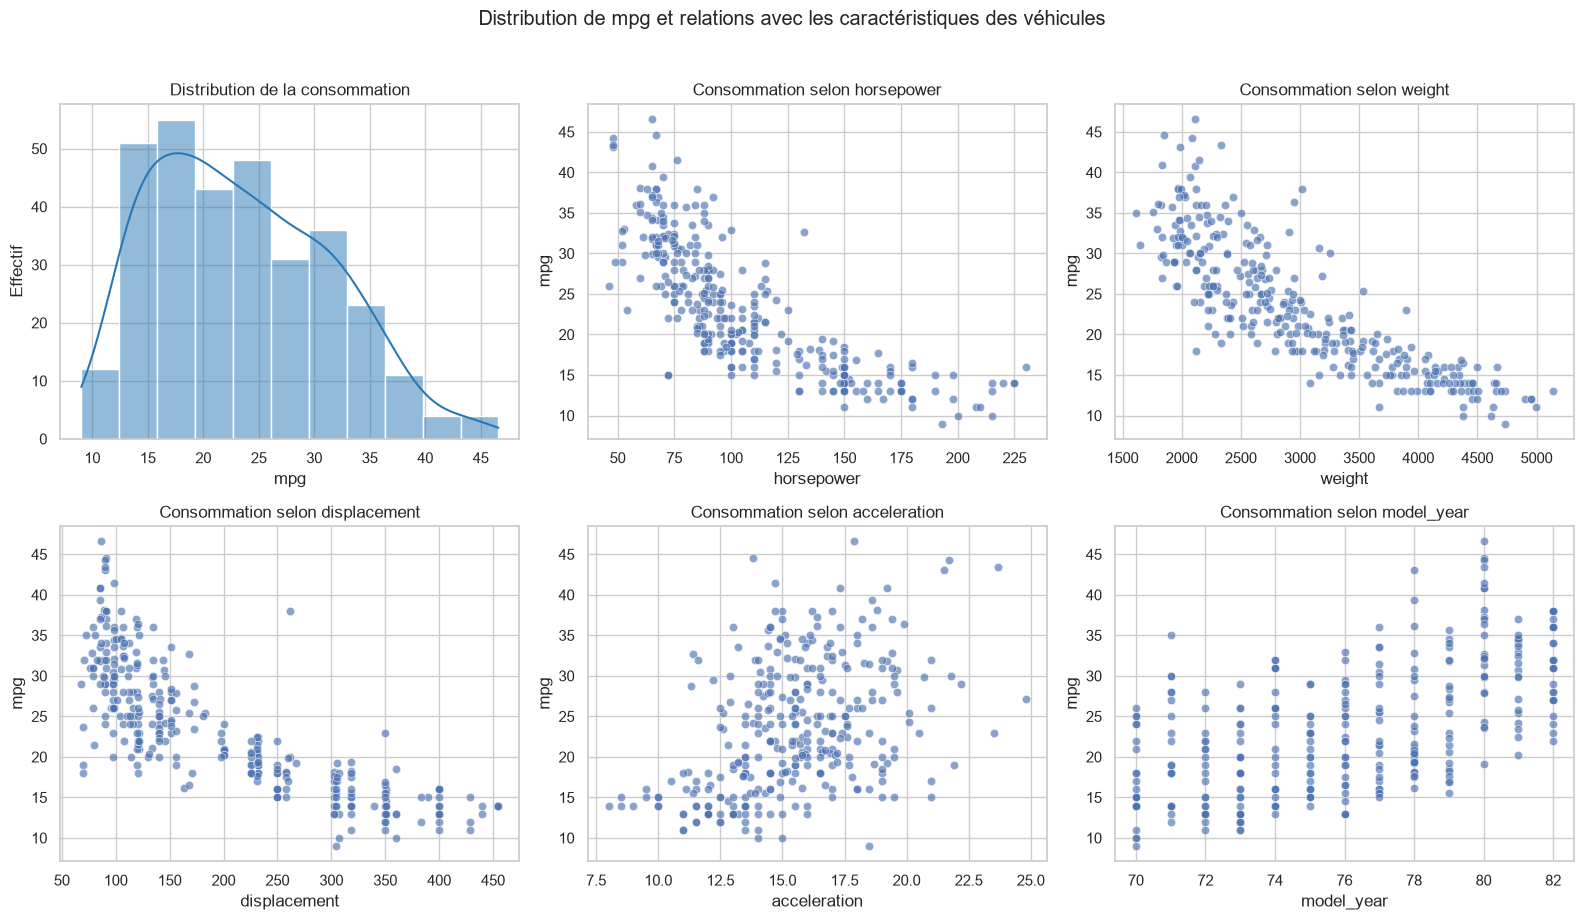

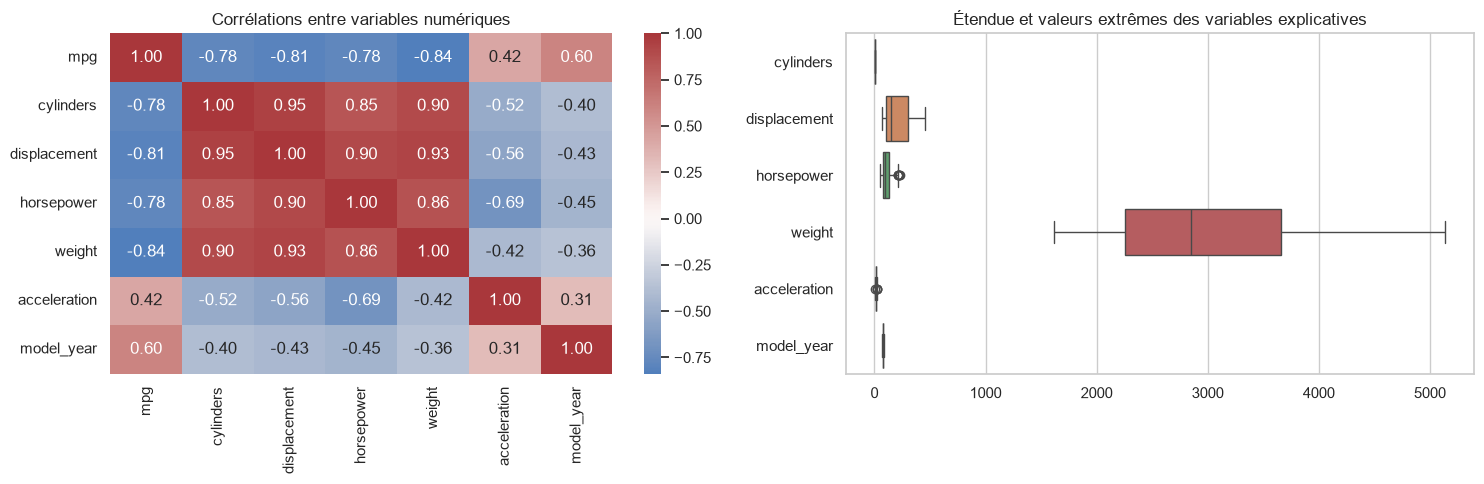

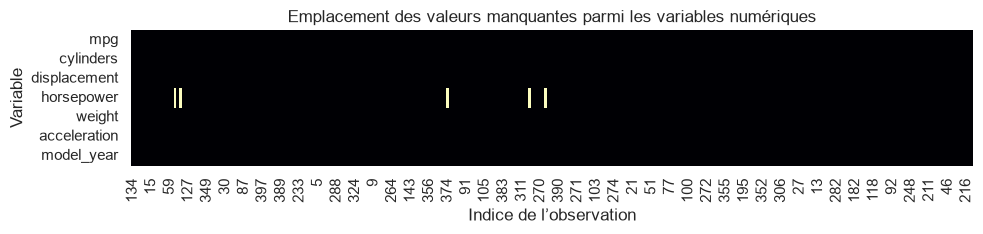

,count,mean,median,std
origin,,,,
europe,58,27.486207,26.0,6.474849
japan,61,30.944262,32.0,6.368792
usa,199,19.942714,18.2,6.470355


,corrélation de Pearson avec mpg
weight,-0.838088
displacement,-0.808225
horsepower,-0.780304
cylinders,-0.780224
acceleration,0.423716
model_year,0.604618


Corrélations mécaniques : weight–displacement = 0.928 ; displacement–cylinders = 0.95


,variable,candidats Tukey,effectif,minimum,maximum
0,cylinders,0,318,3.0,8.0
1,displacement,0,318,68.0,455.0
2,horsepower,7,313,46.0,230.0
3,weight,0,318,1613.0,5140.0
4,acceleration,4,318,8.0,24.8
5,model_year,0,318,70.0,82.0


Indices horsepower manquants : [336, 126, 374, 354, 330]
Asymétrie de mpg : 0.454


In [5]:
variables_num = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.histplot(data=train_brut, x="mpg", kde=True, ax=axes[0, 0], color="#2878B5")
axes[0, 0].set_title("Distribution de la consommation")
axes[0, 0].set_ylabel("Effectif")
for ax, variable in zip(axes.flat[1:], ["horsepower", "weight", "displacement", "acceleration", "model_year"]):
    sns.scatterplot(data=train_brut, x=variable, y="mpg", alpha=0.65, ax=ax)
    ax.set_title(f"Consommation selon {variable}")
fig.suptitle("Distribution de mpg et relations avec les caractéristiques des véhicules", y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
corr = train_brut[variables_num].corr()
sns.heatmap(corr, annot=True, cmap="vlag", center=0, fmt=".2f", ax=axes[0])
axes[0].set_title("Corrélations entre variables numériques")
sns.boxplot(data=train_brut[variables_num].drop(columns="mpg"), orient="h", ax=axes[1])
axes[1].set_title("Étendue et valeurs extrêmes des variables explicatives")
fig.tight_layout()
plt.show()

plt.figure(figsize=(10, 2.5))
sns.heatmap(train_brut[variables_num].isna().T, cbar=False, yticklabels=True, cmap="magma")
plt.title("Emplacement des valeurs manquantes parmi les variables numériques")
plt.xlabel("Indice de l’observation")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

display(train_brut.groupby("origin", observed=True)["mpg"].agg(["count", "mean", "median", "std"]))

correlations_mpg = corr["mpg"].drop("mpg").sort_values()
display(correlations_mpg.rename("corrélation de Pearson avec mpg").to_frame())
print("Corrélations mécaniques : weight–displacement =", round(train_brut[["weight", "displacement"]].corr().iloc[0,1],3),
      "; displacement–cylinders =", round(train_brut[["displacement", "cylinders"]].corr().iloc[0,1],3))
diagnostic_iqr = []
for variable in ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]:
    valeurs = train_brut[variable].dropna(); q1, q3 = valeurs.quantile([0.25, 0.75]); iqr = q3-q1
    nombre = int(((valeurs < q1-1.5*iqr) | (valeurs > q3+1.5*iqr)).sum())
    diagnostic_iqr.append({"variable":variable,"candidats Tukey":nombre,"effectif":len(valeurs),"minimum":valeurs.min(),"maximum":valeurs.max()})
display(pd.DataFrame(diagnostic_iqr))
print("Indices horsepower manquants :", train_brut.index[train_brut["horsepower"].isna()].tolist())
print("Asymétrie de mpg :", round(train_brut["mpg"].skew(),3))


### Ce que révèle l’analyse exploratoire et ses conséquences sur le prétraitement

Tous les constats quantitatifs ci-dessous portent sur les **318 observations d’entraînement**. `mpg` s’étend de **9 à 46,6**, avec une moyenne de **23,43**, une médiane de **22,35** et une asymétrie positive modérée de **0,454**. La distribution reste large; comparer la discrétisation à largeur égale et celle par quantiles est donc utile, sans présumer de leur équilibre dans le test.

Les corrélations de Pearson dans l’entraînement entre `mpg` et les variables numériques sont : `weight` **−0,838**, `displacement` **−0,808**, `cylinders` **−0,780**, `horsepower` **−0,780**, `model_year` **+0,605** et `acceleration` **+0,424**. Les associations mécaniques sont fortes mais les nuages restent dispersés et parfois courbes; un noyau RBF mérite d’être comparé à l’hyperplan linéaire, sans supposer un gain. L’année-modèle est liée à une consommation supérieure dans les modèles plus récents; l’accélération est plus diffuse.

Les moyennes d’entraînement par origine sont **19,94 mpg** aux États-Unis, **27,49** en Europe et **30,94** au Japon. Ce sont des écarts descriptifs, sans interprétation causale. `weight` et `displacement` corrèlent à **0,928**, et `displacement` avec `cylinders` à **0,950** : la redondance motive d’essayer des sous-ensembles pour KNN, mais ne suffit pas à exclure une mesure des SVM/SVR.

Les clôtures de Tukey calculées sur l’entraînement signalent **7 valeurs candidates** pour `horsepower` et **4** pour `acceleration`; les autres variables explicatives ne dépassent pas ces clôtures. Une candidate statistique n’est pas forcément une erreur. Les valeurs sont conservées sans écrêtage, avec cette sensibilité aux valeurs extrêmes signalée pour les modèles quadratiques.

La carte des manques montre cinq `horsepower` absents dans l’entraînement; le sixième reste dans le jeu réservé. **Conséquences :** standardiser les distances et marges, comparer les frontières linéaire et RBF, évaluer les caractéristiques redondantes, encoder `origin` en indicatrices et imputer sans `mpg`.

## 4. Sélection des variables et choix de représentation

Les associations du tableau sont calculées uniquement sur l’entraînement. Elles motivent des essais, mais ne constituent pas un filtre automatique.

| Variable | Sens physique et observation dans l’entraînement | Décision motivée |
|---|---|---|
| `cylinders` | Nombre entier ordonné; $r_{\mathrm{mpg,cylinders}}\approx -0{,}780$, lié à la taille du moteur | Garder numériquement pour respecter l’ordre; comparer aussi le codage par indicatrices |
| `displacement` | Cylindrée; $r_{\mathrm{mpg,displacement}}\approx -0{,}808$ | Garder dans les modèles et évaluer comme mesure mécanique pour KNN |
| `horsepower` | Puissance; $r_{\mathrm{mpg,horsepower}}\approx -0{,}780$; cinq manques d’entraînement | Imputer puis conserver comme prédicteur important |
| `weight` | Masse; corrélation la plus forte avec `mpg`, $r_{\mathrm{mpg,weight}}\approx -0{,}838$ | Garder en SVM/SVR; tester en KNN en raison du recouvrement avec la cylindrée |
| `acceleration` | Mesure continue; corrélation plus faible, $r_{\mathrm{mpg,acceleration}}\approx 0{,}424$ et nuage diffus | Conserver comme information complémentaire plutôt que conclure à son inutilité |
| `model_year` | Année-modèle ordonnée; $r_{\mathrm{mpg,model\_year}}\approx 0{,}605$ | Garder pour représenter la tendance temporelle |
| `origin` | Origine nominale; moyennes d’entraînement distinctes selon les régions | Encoder en indicatrices afin de ne pas imposer d’ordre arbitraire |
| `name` | 252 chaînes distinctes sur 318 observations d’entraînement | Exclure : identifiant textuel cardinal, sans mesure mécanique exploitable |

`weight` et `displacement` corrèlent à **0,928**; `displacement` et `cylinders`, à **0,950**. Cette redondance justifie la comparaison de combinaisons KNN; elle ne prouve pas qu’une variable est inutile dans un modèle régularisé.

Les objectifs restent distincts : KNN estime `horsepower` avec des propriétés mécaniques; SVM/SVR prédisent `mpg`. Utiliser `mpg` dans la distance d’imputation transmettrait la réponse au prétraitement.

## 5. Mise à l’échelle : justification, formules et fuites

Dans l’entraînement, `weight` varie de **1 613 à 5 140**, `displacement` de **68 à 455** et `acceleration` de **8,0 à 24,8**. Les différences d’amplitude peuvent faire dominer une distance brute par les unités les plus grandes. Les marges et la pénalité quadratique des SVM/SVR dépendent aussi des unités; la standardisation place les variables numériques sur des échelles comparables et peut améliorer le conditionnement de l’optimisation.

La normalisation min-max transforme une valeur selon l’étendue observée, $x'=\frac{x-x_{\min}}{x_{\max}-x_{\min}}$; elle vise souvent une plage bornée, mais dépend des extrêmes. La standardisation centre chaque variable par sa moyenne et la divise par son écart-type :

$$
\mu_j=\frac{1}{n}\sum_{i=1}^{n}x_{ij},\quad
\sigma_j=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\mu_j)^2},\quad
z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.
$$

Nous utilisons l’écart-type de population (`ddof=0`, dénominateur $n$). La standardisation ne rend pas les variables gaussiennes et ne supprime pas les valeurs extrêmes.

Le standardiseur mémorise ses statistiques sur l’entraînement seulement. Les recalculer avec les observations de test ferait intervenir des informations indisponibles lors d’une prédiction réelle : ce serait une fuite de données. La transformation du test réutilise donc les statistiques apprises.

Si une variable est constante à l’entraînement, nous remplaçons son écart-type nul par 1 : la colonne constante devient zéro sans division par zéro. Deux objets indépendants sont requis, car les variables et objectifs du KNN diffèrent des entrées finales SVM/SVR; les indicatrices d’origine restent à 0/1.

## 6. Implémentation et vérification de `MyStandardScaler`

La conception sépare trois opérations. `fit(X)` vérifie que la matrice est bidimensionnelle, non vide, numérique et finie; elle stocke le nombre de colonnes, les noms et l’ordre des DataFrames, les moyennes, variances de population et échelles. `transform(X)` vérifie les dimensions et l’ordre, puis n’utilise que ces valeurs apprises. `fit_transform(X)` ajuste avant de transformer.

L’exemple ci-dessous compare deux colonnes variables et une constante à `sklearn.preprocessing.StandardScaler`, utilisé uniquement comme référence de vérification. Une quatrième observation représente le test; sa transformation doit réutiliser les statistiques mémorisées.

In [6]:
class MyStandardScaler:
    """Standardisation avec écart-type de population (ddof=0), implémentée à la main."""

    def _tableau(self, X, pour_fit=False):
        est_df = isinstance(X, pd.DataFrame)
        if est_df:
            if pour_fit:
                if not X.columns.is_unique:
                    raise ValueError("Les noms de colonnes doivent être uniques.")
                noms = list(X.columns)
            else:
                noms = list(X.columns)
                if hasattr(self, "feature_names_in_") and noms != list(self.feature_names_in_):
                    raise ValueError("Les colonnes du DataFrame doivent correspondre exactement à l’ordre appris.")
            valeurs = X.to_numpy(dtype=float)
        else:
            valeurs = np.asarray(X, dtype=float)
            noms = None
        if valeurs.ndim != 2:
            raise ValueError("X doit être une matrice bidimensionnelle.")
        if valeurs.shape[0] == 0 or valeurs.shape[1] == 0:
            raise ValueError("X doit contenir au moins une observation et une variable.")
        if not np.isfinite(valeurs).all():
            raise ValueError("X ne doit contenir que des valeurs numériques finies.")
        return valeurs, noms, est_df

    def fit(self, X):
        valeurs, noms, _ = self._tableau(X, pour_fit=True)
        self.n_features_in_ = valeurs.shape[1]
        if noms is not None:
            self.feature_names_in_ = np.asarray(noms, dtype=object)
        self.mean_ = valeurs.mean(axis=0)
        self.var_ = ((valeurs - self.mean_) ** 2).mean(axis=0)
        ecarts = np.sqrt(self.var_)
        self.zero_variance_ = ecarts == 0
        self.scale_ = np.where(self.zero_variance_, 1.0, ecarts)
        return self

    def transform(self, X):
        if not hasattr(self, "mean_"):
            raise RuntimeError("Appeler fit avant transform.")
        valeurs, noms, est_df = self._tableau(X)
        if valeurs.shape[1] != self.n_features_in_:
            raise ValueError("Le nombre de variables ne correspond pas à celui appris.")
        resultat = (valeurs - self.mean_) / self.scale_
        if est_df:
            return pd.DataFrame(resultat, index=X.index, columns=X.columns)
        return resultat

    def fit_transform(self, X):
        return self.fit(X).transform(X)


exemple = pd.DataFrame({"largeur": [1.0, 2.0, 3.0], "hauteur": [2.0, 4.0, 6.0], "constante": [7.0, 7.0, 7.0]})
standardiseur_exemple = MyStandardScaler().fit(exemple)
sortie_maison = standardiseur_exemple.transform(exemple)
print("Moyennes apprises :", standardiseur_exemple.mean_)
print("Écarts-types de population :", np.sqrt(standardiseur_exemple.var_))
print("Variables de variance nulle :", list(exemple.columns[standardiseur_exemple.zero_variance_]))
display(sortie_maison)

from sklearn.preprocessing import StandardScaler  # référence uniquement pour cet exemple
sortie_reference = StandardScaler().fit_transform(exemple)
print("Accord avec StandardScaler (tolérance numérique) :", np.allclose(sortie_maison, sortie_reference))
assert np.allclose(sortie_maison, sortie_reference)

exemple_test = pd.DataFrame({"largeur": [4.0], "hauteur": [8.0], "constante": [7.0]})
display(standardiseur_exemple.transform(exemple_test))

Moyennes apprises : [2. 4. 7.]
Écarts-types de population : [0.81649658 1.63299316 0.        ]
Variables de variance nulle : ['constante']


,largeur,hauteur,constante
0,-1.224745,-1.224745,0.0
1,0.000000,0.000000,0.0
2,1.224745,1.224745,0.0


Accord avec StandardScaler (tolérance numérique) : True


,largeur,hauteur,constante
0,2.44949,2.44949,0.0


### Lecture des résultats — vérification du standardiseur

L’exemple donne les moyennes `[2, 4, 7]` et écarts-types population `[0,8165, 1,6330, 0]`. La colonne constante est protégée par une échelle 1 et devient zéro. Les colonnes variables ressortent centrées et réduites. `np.allclose` confirme l’accord avec scikit-learn **dans ce seul exemple de vérification**.

La ligne test est transformée en environ `[2,4495, 2,4495, 0]` grâce aux statistiques déjà mémorisées. Elle n’est pas utilisée pour recalculer sa propre moyenne ou son écart-type; c’est le comportement requis pour éviter la fuite.

## 7. Vérification du partage entraînement/test avant l’analyse et les traitements appris

La partition de 20 % est créée après l’inventaire du schéma. Pour éviter la différence de proportions de classes observée auparavant, les lignes sont stratifiées selon trois bandes provisoires de `mpg` et la présence d’une valeur `horsepower` manquante. Ces bandes ne servent qu’à répartir les observations : les seuils de classification restent calculés sur l’entraînement, et aucun scaler, imputeur ou modèle n’est ajusté à partir du test. La graine fixe rend le partage reproductible.

La stratification utilise donc le rang de `mpg` uniquement comme variable de répartition; les cibles de test demeurent réservées à l’évaluation des modèles. La validation artificielle KNN, l’imputation fold-par-fold en validation croisée et les statistiques de prétraitement sont ajustées sur leurs seules références d’entraînement.

In [7]:
# Vérification de la partition créée avant toute analyse exploratoire
assert set(train_brut.index).isdisjoint(set(test_brut.index))
assert set(train_brut.index) | set(test_brut.index) == set(df.index)
audit_partition = pd.DataFrame({
    "partition": ["entraînement", "test réservé"],
    "observations": [len(train_brut), len(test_brut)],
    "horsepower manquant": [int(train_brut["horsepower"].isna().sum()), int(test_brut["horsepower"].isna().sum())],
})
display(audit_partition)
print("La partition est disjointe, exhaustive et a été fixée avant l’analyse exploratoire.")

,partition,observations,horsepower manquant
0,entraînement,318,5
1,test réservé,80,1


La partition est disjointe, exhaustive et a été fixée avant l’analyse exploratoire.


### Lecture des résultats — séparation et flux

La partition reproductible comporte **318 observations d’entraînement et 80 de test**; cinq puissances manquent dans l’entraînement et une dans le jeu réservé. La stratification utilise des tiers provisoires de `mpg` et le statut des manques uniquement pour répartir les lignes; les seuils définitifs des classes sont calculés sur l’entraînement.

Flux de traitement : séparation avant analyse exploratoire → validation KNN interne → imputation avec références d’entraînement → seuils et catégories appris sur l’entraînement → standardisation finale ajustée sur l’entraînement → transformation du test avec les mêmes objets → évaluation. Le jeu de test n’ajuste aucun traitement et ne sert pas de référence pour KNN.

## 8. Valeurs manquantes et investigation KNN

Six valeurs manquent dans `horsepower`. La suppression complète donnerait 392 véhicules, soit six observations (1,5 %) perdues, et ne produit pas de puissance estimée. La moyenne conserve les lignes mais efface toute différence entre moteurs; la médiane est robuste aux valeurs extrêmes, mais reste constante. KNN est étudié car cylindrée, masse et cylindres décrivent des propriétés mécaniques liées à la puissance.

Pour une requête $x$, la distance et l’estimation uniforme sont

$$
d(x,x_i)=\sqrt{\sum_{j=1}^{p}(x_j-x_{ij})^2},\qquad
\hat{h}(x)=\frac{1}{k}\sum_{i\in\mathcal{N}_k(x)}h_i.
$$

Nous codons nous-mêmes la distance, le tri des voisins et la moyenne. Sans standardisation, les colonnes à large amplitude domineraient la distance; chaque standardiseur KNN de validation est donc ajusté seulement sur ses références connues. La moyenne uniforme respecte la formule demandée et évite un paramètre additionnel; la pondération inverse de distance reste une alternative non testée.

Des puissances connues sont artificiellement masquées. Les observations masquées sont retirées des références; MAE et RMSE évaluent $k=3,\,5,\,7$, plusieurs combinaisons de variables et distances brutes/standardisées. La sélection finale se fait sur la RMSE interne, jamais sur le test.

In [8]:
def distance_euclidienne(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.ndim != 1 or b.ndim != 1 or a.shape != b.shape:
        raise ValueError("Les deux vecteurs doivent être unidimensionnels et de même longueur.")
    return float(np.sqrt(np.sum((a - b) ** 2)))


def predire_knn_une_ligne(requete, X_reference, y_reference, k):
    if k < 1 or k > len(X_reference):
        raise ValueError("k doit être compris entre 1 et le nombre de références.")
    distances = np.array([distance_euclidienne(requete, ligne) for ligne in X_reference])
    voisins = np.argsort(distances, kind="stable")[:k]
    return float(np.mean(np.asarray(y_reference)[voisins]))


def transformer_knn(X, standardiseur=None):
    if standardiseur is None:
        return X.to_numpy(dtype=float)
    return standardiseur.transform(X).to_numpy(dtype=float)


connues_train = train_brut.loc[train_brut["horsepower"].notna()].copy()
idx_reference, idx_validation = train_test_split(
    connues_train.index.to_numpy(), test_size=0.20, random_state=RANDOM_STATE
)
reference_validation = connues_train.loc[idx_reference]
validation = connues_train.loc[idx_validation]

combinaisons = [
    ["displacement", "weight", "cylinders"],
    ["displacement", "weight"],
    ["weight", "cylinders"],
    ["displacement", "cylinders"],
    ["weight"],
]
resultats_knn = []
for variables in combinaisons:
    for k in (3, 5, 7):
        for standardiser in (False, True):
            standardiseur_temp = MyStandardScaler().fit(reference_validation[variables]) if standardiser else None
            X_ref = transformer_knn(reference_validation[variables], standardiseur_temp)
            X_val = transformer_knn(validation[variables], standardiseur_temp)
            predictions = np.array([
                predire_knn_une_ligne(x, X_ref, reference_validation["horsepower"].to_numpy(), k)
                for x in X_val
            ])
            y_val = validation["horsepower"].to_numpy(dtype=float)
            resultats_knn.append({
                "variables": ", ".join(variables), "k": k, "distance standardisée": standardiser,
                "MAE": mean_absolute_error(y_val, predictions),
                "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
            })

table_knn = pd.DataFrame(resultats_knn).sort_values(["RMSE", "MAE"]).reset_index(drop=True)
display(table_knn)
methodes_reference = []
for methode, valeur in [("moyenne de référence", reference_validation["horsepower"].mean()), ("médiane de référence", reference_validation["horsepower"].median())]:
    pred = np.full(len(validation), valeur, dtype=float)
    methodes_reference.append({"méthode":methode,"valeur":valeur,"MAE":mean_absolute_error(validation["horsepower"],pred),"RMSE":np.sqrt(mean_squared_error(validation["horsepower"],pred))})
tableau_references_knn = pd.DataFrame(methodes_reference)
print("Méthodes de référence calculées uniquement à partir des références d’entraînement :")
display(tableau_references_knn)
meilleure_ligne = table_knn[table_knn["distance standardisée"]].iloc[0]
meilleures_variables_knn = meilleure_ligne["variables"].split(", ")
meilleur_k = int(meilleure_ligne["k"])
print("Configuration finale (choisie sur validation d’entraînement) :", meilleure_ligne.to_dict())

# Le standardiseur KNN final est ajusté sur les seules observations de référence de l’entraînement.
standardiseur_knn = MyStandardScaler().fit(connues_train[meilleures_variables_knn])
X_reference_final = standardiseur_knn.transform(connues_train[meilleures_variables_knn]).to_numpy(dtype=float)
y_reference_final = connues_train["horsepower"].to_numpy(dtype=float)

def completer_puissance(partition):
    resultat = partition.copy()
    a_completer = resultat["horsepower"].isna()
    if a_completer.any():
        X_requetes = standardiseur_knn.transform(resultat.loc[a_completer, meilleures_variables_knn]).to_numpy(dtype=float)
        estimations = [predire_knn_une_ligne(x, X_reference_final, y_reference_final, meilleur_k) for x in X_requetes]
        resultat.loc[a_completer, "horsepower"] = estimations
    return resultat

train = completer_puissance(train_brut)
test = completer_puissance(test_brut)
assert train["horsepower"].notna().all() and test["horsepower"].notna().all()
print("Valeurs imputées — entraînement :", int(train_brut["horsepower"].isna().sum()))
print("Valeurs imputées — test à partir des références d’entraînement :", int(test_brut["horsepower"].isna().sum()))

,variables,k,distance standardisée,MAE,RMSE
0,"displacement, weight, cylinders",7,True,9.210884,12.826721
1,"displacement, weight, cylinders",5,True,9.841270,13.287301
2,"displacement, weight, cylinders",3,True,9.894180,13.413516
3,"displacement, weight",7,True,9.789116,13.422503
4,"displacement, cylinders",7,False,9.471655,13.469242
5,"displacement, cylinders",3,True,9.312169,13.479097
6,"displacement, cylinders",7,True,9.587302,13.500507
7,"displacement, weight",3,True,10.126984,13.568300
8,"weight, cylinders",7,True,11.104308,13.647406
9,"displacement, cylinders",5,True,9.914286,13.834693


Méthodes de référence calculées uniquement à partir des références d’entraînement :


,méthode,valeur,MAE,RMSE
0,moyenne de référence,106.544,29.338667,35.970324
1,médiane de référence,92.000,27.777778,37.992063


Configuration finale (choisie sur validation d’entraînement) : {'variables': 'displacement, weight, cylinders', 'k': 7, 'distance standardisée': True, 'MAE': 9.210884353741495, 'RMSE': 12.826721379257751}
Valeurs imputées — entraînement : 5
Valeurs imputées — test à partir des références d’entraînement : 1


### Résultats et décision — validation KNN

La configuration la plus performante de la validation interne standardise les variables `displacement`, `weight` et `cylinders`, avec **$k=7$** : MAE **9,21 hp** et RMSE **12,83 hp**. Elle améliore les références entraînées sur la moyenne (MAE 29,34 hp) et la médiane (27,78 hp). Les configurations proches ont des erreurs supérieures; la décision est donc conservée pour l’imputation finale. Cette estimation provient d’un masquage artificiel unique, et non d’une validation répétée.

Les cinq valeurs manquantes d’entraînement sont imputées à partir des références connues d’entraînement. La puissance manquante du test est imputée avec ce même ensemble de références et les mêmes statistiques du scaler KNN; elle ne participe jamais à leur ajustement.


## 9. Discrétisation de la cible et prétraitement final

La classification exige une cible catégorielle; la variable continue `mpg` restera intacte pour le SVR.

La méthode à largeur égale découpe l’étendue d’entraînement en trois intervalles de même amplitude : $b_r=m_{\min}+\frac{r(m_{\max}-m_{\min})}{3}$, pour $r=1,2$. Elle donne des seuils interprétables en unité mpg, mais une distribution asymétrique peut produire des effectifs très inégaux. La méthode par quantiles place les coupures aux rangs $\frac{1}{3}$ et $\frac{2}{3}$; elle vise des groupes de même taille, mais ses bornes dépendent de l’échantillon et peuvent être affectées par les valeurs ex æquo.

Nous comparerons seuils, effectifs et proportions dans l’entraînement et le jeu de test. Le choix doit considérer à la fois l’équilibre des classes et le sens des bornes : les quantiles ne constituent pas des seuils réglementaires ni des catégories d’économie automobile reconnues. Le codage de `origin` est appris sur l’entraînement puis aligné sur le test. Un autre `MyStandardScaler`, indépendant du standardiseur KNN, ajuste ensuite les variables numériques finales sur l’entraînement; les colonnes binaires d’origine restent à 0/1.

In [9]:
NOMS_CLASSES = np.array(["faible", "moyenne", "élevée"])
y_mpg_train = train["mpg"].to_numpy(dtype=float)
y_mpg_test = test["mpg"].to_numpy(dtype=float)

bornes_largeur = np.linspace(y_mpg_train.min(), y_mpg_train.max(), 4)
seuils_quantiles = np.quantile(y_mpg_train, [1/3, 2/3])

def etiqueter_mpg(valeurs, seuils):
    return np.digitize(np.asarray(valeurs, dtype=float), seuils, right=False).astype(int)

y_train_largeur = etiqueter_mpg(y_mpg_train, bornes_largeur[1:-1])
y_test_largeur = etiqueter_mpg(y_mpg_test, bornes_largeur[1:-1])
y_train_classes = etiqueter_mpg(y_mpg_train, seuils_quantiles)
y_test_classes = etiqueter_mpg(y_mpg_test, seuils_quantiles)

def tableau_effectifs(y, partition, methode):
    compte = pd.Series(y).value_counts().reindex(range(3), fill_value=0)
    return pd.DataFrame({"méthode": methode, "partition": partition, "classe": NOMS_CLASSES, "effectif": compte.to_numpy(), "proportion": compte.to_numpy()/len(y)})

distribution_classes = pd.concat([
    tableau_effectifs(y_train_largeur, "entraînement", "largeur égale"),
    tableau_effectifs(y_test_largeur, "test", "largeur égale"),
    tableau_effectifs(y_train_classes, "entraînement", "quantiles"),
    tableau_effectifs(y_test_classes, "test", "quantiles"),
], ignore_index=True)
print("Bornes largeur égale (calculées sur l’entraînement) :", bornes_largeur)
print("Seuils quantiles (calculés sur l’entraînement) :", seuils_quantiles)
display(distribution_classes)

VARIABLES_NUMERIQUES = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
variables_origin = sorted(train["origin"].dropna().unique().tolist())
colonnes_origin = [f"origin_{valeur}" for valeur in variables_origin]

def encoder_origin(partition):
    codes = partition["origin"].to_numpy()
    matrice = np.column_stack([(codes == valeur).astype(float) for valeur in variables_origin])
    return pd.DataFrame(matrice, index=partition.index, columns=colonnes_origin)

origin_train_df = encoder_origin(train)
origin_test_df = encoder_origin(test)
standardiseur_final = MyStandardScaler().fit(train[VARIABLES_NUMERIQUES])
train_numerique_echelle = standardiseur_final.transform(train[VARIABLES_NUMERIQUES])
test_numerique_echelle = standardiseur_final.transform(test[VARIABLES_NUMERIQUES])
X_train_df = pd.concat([train_numerique_echelle, origin_train_df], axis=1)
X_test_df = pd.concat([test_numerique_echelle, origin_test_df], axis=1)
origines_inconnues_test = set(test["origin"].dropna().unique()) - set(variables_origin)
print("Origines encodées à partir de l’entraînement :", variables_origin, "; origines inconnues dans le test :", origines_inconnues_test)
X_train = X_train_df.to_numpy(dtype=float)
X_test = X_test_df.to_numpy(dtype=float)
print("Ordre final des caractéristiques :", list(X_train_df.columns))
print("Dimensions des matrices finales :", X_train.shape, "et", X_test.shape)
print("Statistiques finales du standardiseur (entraînement) :")
display(pd.DataFrame({"moyenne": standardiseur_final.mean_, "écart-type ddof=0": np.sqrt(standardiseur_final.var_)}, index=VARIABLES_NUMERIQUES))


Bornes largeur égale (calculées sur l’entraînement) : [ 9.         21.53333333 34.06666667 46.6       ]
Seuils quantiles (calculés sur l’entraînement) : [18.83333333 27.        ]


,méthode,partition,classe,effectif,proportion
0,largeur égale,entraînement,faible,147,0.462264
1,largeur égale,entraînement,moyenne,136,0.427673
2,largeur égale,entraînement,élevée,35,0.110063
3,largeur égale,test,faible,36,0.450000
4,largeur égale,test,moyenne,35,0.437500
5,largeur égale,test,élevée,9,0.112500
6,quantiles,entraînement,faible,106,0.333333
7,quantiles,entraînement,moyenne,105,0.330189
8,quantiles,entraînement,élevée,107,0.336478
9,quantiles,test,faible,25,0.312500


Origines encodées à partir de l’entraînement : ['europe', 'japan', 'usa'] ; origines inconnues dans le test : set()
Ordre final des caractéristiques : ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_europe', 'origin_japan', 'origin_usa']
Dimensions des matrices finales : (318, 9) et (80, 9)
Statistiques finales du standardiseur (entraînement) :


,moyenne,écart-type ddof=0
cylinders,5.493711,1.716996
displacement,196.320755,105.555275
horsepower,105.756963,39.290942
weight,3004.427673,852.464588
acceleration,15.454717,2.779093
model_year,76.066038,3.694128


### Lecture des résultats — coupures et matrices finales

Les bornes de largeur égale calculées sur l’entraînement sont **21,53** et **34,07 mpg**. Les classes d’entraînement comptent **147, 136 et 35** observations (**46,2 %, 42,8 % et 11,0 %**); le test en contient **36, 35 et 9** (**45,0 %, 43,8 % et 11,3 %**). La classe élevée reste nettement minoritaire avec cette discrétisation.

Les seuils quantiles d’entraînement sont **18,83** et **27,00 mpg**. Les effectifs d’entraînement sont **106, 105 et 107** (**33,3 %, 33,0 % et 33,6 %**); le test comporte **25, 29 et 26** cas (**31,3 %, 36,3 % et 32,5 %**). La stratification rend la composition du test plus proche de celle de l’entraînement, sans imposer des proportions exactement égales.

Nous retenons les quantiles pour l’analyse principale car ils évitent une classe d’entraînement élevée de seulement 35 véhicules. Les modèles sont aussi entraînés et évalués avec les étiquettes à largeur égale dans une analyse de sensibilité. Les seuils demeurent propres à cet échantillon et n’ont pas d’interprétation métier universelle; la cible continue reste intacte pour le SVR.

La matrice finale contient neuf colonnes : six variables numériques standardisées par un scaler ajusté sur l’entraînement et trois indicatrices `origin` non standardisées. Les modalités sont apprises sur l’entraînement puis alignées sur le test.


## 10. Fondements mathématiques des SVM

Pour des étiquettes binaires $y_i\in\{-1,+1\}$, l’hyperplan est $f(x)=w^\top x+b=0$. Les hyperplans de marge $f=\pm1$ sont séparés par $2/\|w\|$; minimiser $\frac12\|w\|^2$ maximise donc la marge. Les observations sur ou à l’intérieur de la marge sont les vecteurs de support.

La perte charnière $\ell_i=\max(0,1-y_if_i)$ pénalise les points mal classés ou trop proches. Le problème souple minimise $\frac12\|w\|^2+C\sum_i\ell_i$. Un $C$ grand pénalise davantage les violations; un $C$ faible privilégie une frontière plus régularisée.

Dans le dual à noyau, les coefficients sont contraints par $0\leq\alpha_i\leq C$ et $\sum_i\alpha_i y_i=0$. Le noyau remplace les produits scalaires par des similarités; SMO ajuste deux multiplicateurs à la fois pour conserver la contrainte d’égalité.

## 11. SVM linéaire et extension un-contre-tous

Pour $A=\{i:y_if_i<1\}$, un sous-gradient de la perte charnière est $w-C\sum_{i\in A}y_ix_i$ et $-C\sum_{i\in A}y_i$ pour le biais. Le code minimise un multiple positif équivalent de l’objectif demandé,

$$
J(\mathbf{w},b)=\frac{1}{2Cn}\|\mathbf{w}\|^2+
\frac{1}{n}\sum_{i=1}^{n}\max(0,1-y_if_i).
$$

dont les sous-gradients sont divisés par $n$. Le biais n’est pas régularisé. Après comparaison de $C \in \{0{,}1;\,1;\,10\}$ par F1 macro moyen sur trois plis stratifiés de l’entraînement, le modèle final utilise le $C$ retenu, 5 000 itérations et $\eta_t=0{,}15/\sqrt{1+t/250}$; le pas décroît. L’algorithme garde ce budget fixe, enregistre l’objectif normalisé à intervalles et le dernier déplacement. Ce dernier est un diagnostic, pas une certification KKT.

La cible a trois classes; un-contre-tous entraîne faible contre reste, moyenne contre reste et élevée contre reste, puis choisit le score le plus élevé. Cette stratégie réutilise directement un classifieur binaire et rend les trois tâches inspectables. Un-contre-un serait une alternative à vote, non retenue.

La grille $C \in \{0{,}1;\,1;\,10\}$ est évaluée par validation croisée stratifiée à trois plis, uniquement dans l’entraînement. À chaque pli, le standardiseur KNN et la standardisation finale sont ajustés sur les seules références du pli d’apprentissage; les lignes de validation ne servent ni à imputer ni à calculer les statistiques. Le C retenu maximise le F1 macro moyen; le jeu de test ne sert pas au réglage.


In [10]:
class SVMLineaireBinaire:
    def __init__(self, C=1.0, iterations=5000, taux=0.15):
        if C <= 0 or iterations < 1 or taux <= 0:
            raise ValueError("C, le nombre d’itérations et le taux doivent être positifs.")
        self.C, self.iterations, self.taux = float(C), int(iterations), float(taux)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.ndim != 1 or len(y) != len(X) or not set(np.unique(y)).issubset({-1.0, 1.0}):
            raise ValueError("X doit être une matrice et y un vecteur binaire codé en -1/+1.")
        n, p = X.shape
        self.w_ = np.zeros(p)
        self.b_ = 0.0
        lambda_reg = 1.0 / (self.C * n)
        def objectif_normalise():
            marges = y * (X @ self.w_ + self.b_)
            return float(0.5 * lambda_reg * np.dot(self.w_, self.w_) + np.maximum(0, 1 - marges).mean())
        self.objective_history_ = [objectif_normalise()]
        for iteration in range(self.iterations):
            marges = y * (X @ self.w_ + self.b_)
            actifs = marges < 1.0
            grad_w = lambda_reg * self.w_ - (X[actifs].T @ y[actifs]) / n
            grad_b = -np.sum(y[actifs]) / n
            pas = self.taux / np.sqrt(1.0 + iteration / 250.0)
            delta_w = pas * grad_w
            delta_b = pas * grad_b
            self.w_ -= delta_w
            self.b_ -= delta_b
            self.last_update_norm_ = float(np.sqrt(np.dot(delta_w, delta_w) + delta_b ** 2))
            if (iteration + 1) % 1000 == 0:
                self.objective_history_.append(objectif_normalise())
        marges_fin = y * (X @ self.w_ + self.b_)
        self.objectif_ = 0.5 * np.dot(self.w_, self.w_) + self.C * np.maximum(0, 1 - marges_fin).sum()
        self.support_mask_ = marges_fin <= 1.0 + 1e-4
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_


class SVMLineaireOvR:
    def __init__(self, C=1.0, iterations=5000, taux=0.15):
        self.parametres = (C, iterations, taux)

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.modeles_ = []
        for classe in self.classes_:
            y_binaire = np.where(np.asarray(y) == classe, 1.0, -1.0)
            modele = SVMLineaireBinaire(*self.parametres).fit(X, y_binaire)
            self.modeles_.append(modele)
        return self

    def decision_function(self, X):
        return np.column_stack([m.decision_function(X) for m in self.modeles_])

    def predict(self, X):
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]


# Préparation fold-par-fold : imputation KNN, puis standardisation numérique ajustée sur le pli d’apprentissage.
def preparer_pli_cv(indices_apprentissage, indices_validation):
    brut_apprentissage = train_brut.iloc[indices_apprentissage].copy()
    brut_validation = train_brut.iloc[indices_validation].copy()
    references_connues = brut_apprentissage.loc[brut_apprentissage["horsepower"].notna()].copy()
    standardiseur_knn_pli = MyStandardScaler().fit(references_connues[meilleures_variables_knn])
    X_references_pli = standardiseur_knn_pli.transform(references_connues[meilleures_variables_knn]).to_numpy(dtype=float)
    y_references_pli = references_connues["horsepower"].to_numpy(dtype=float)

    def imputer_pli(partition):
        sortie = partition.copy()
        masque = sortie["horsepower"].isna()
        if masque.any():
            X_requetes = standardiseur_knn_pli.transform(sortie.loc[masque, meilleures_variables_knn]).to_numpy(dtype=float)
            estimations = [
                predire_knn_une_ligne(x, X_references_pli, y_references_pli, meilleur_k)
                for x in X_requetes
            ]
            sortie.loc[masque, "horsepower"] = estimations
        return sortie

    apprentissage_pli = imputer_pli(brut_apprentissage)
    validation_pli = imputer_pli(brut_validation)
    standardiseur_final_pli = MyStandardScaler().fit(apprentissage_pli[VARIABLES_NUMERIQUES])
    X_apprentissage_numerique = standardiseur_final_pli.transform(apprentissage_pli[VARIABLES_NUMERIQUES])
    X_validation_numerique = standardiseur_final_pli.transform(validation_pli[VARIABLES_NUMERIQUES])
    X_apprentissage_pli = pd.concat([X_apprentissage_numerique, encoder_origin(apprentissage_pli)], axis=1).to_numpy(dtype=float)
    X_validation_pli = pd.concat([X_validation_numerique, encoder_origin(validation_pli)], axis=1).to_numpy(dtype=float)
    return X_apprentissage_pli, X_validation_pli, apprentissage_pli["mpg"].to_numpy(dtype=float), validation_pli["mpg"].to_numpy(dtype=float)

assert train.index.equals(train_brut.index), "L’ordre des cibles et des observations d’entraînement doit correspondre."
plis_cv = []
splitter_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE + 1)
for indices_cv_apprentissage, indices_cv_validation in splitter_cv.split(np.zeros(len(y_train_classes)), y_train_classes):
    X_cv_apprentissage, X_cv_validation, y_mpg_cv_apprentissage, y_mpg_cv_validation = preparer_pli_cv(
        indices_cv_apprentissage, indices_cv_validation
    )
    plis_cv.append((
        X_cv_apprentissage, X_cv_validation,
        y_train_classes[indices_cv_apprentissage], y_train_classes[indices_cv_validation],
        y_mpg_cv_apprentissage, y_mpg_cv_validation,
    ))

C_GRILLE_SVC = [0.1, 1.0, 10.0]
resultats_cv_lineaire = []
for C_candidat in C_GRILLE_SVC:
    scores = []
    for X_cv_apprentissage, X_cv_validation, y_cv_apprentissage, y_cv_validation, _, _ in plis_cv:
        modele_cv = SVMLineaireOvR(C=C_candidat, iterations=5000, taux=0.15).fit(X_cv_apprentissage, y_cv_apprentissage)
        scores.append(f1_score(y_cv_validation, modele_cv.predict(X_cv_validation), average="macro"))
    resultats_cv_lineaire.append({"C": C_candidat, "F1 macro moyen": np.mean(scores), "écart-type entre plis": np.std(scores, ddof=1)})

table_cv_lineaire = pd.DataFrame(resultats_cv_lineaire).sort_values(
    ["F1 macro moyen", "C"], ascending=[False, True]
).reset_index(drop=True)
print("Validation croisée linéaire, trois plis de l’entraînement :")
display(table_cv_lineaire.round(4))
C_lineaire_retenu = float(table_cv_lineaire.iloc[0]["C"])
print("C linéaire sélectionné par F1 macro moyen, sans consulter le test :", C_lineaire_retenu)

modele_lineaire = SVMLineaireOvR(C=C_lineaire_retenu, iterations=5000, taux=0.15).fit(X_train, y_train_classes)
pred_lineaire = modele_lineaire.predict(X_test)
print("Objectifs binaires finaux :", [round(float(m.objectif_),3) for m in modele_lineaire.modeles_])
print("Objectif normalisé initial puis aux 1 000 itérations :", [np.round(m.objective_history_,6).tolist() for m in modele_lineaire.modeles_])
print("Norme du dernier déplacement (w,b) :", [round(m.last_update_norm_,7) for m in modele_lineaire.modeles_])

Validation croisée linéaire, trois plis de l’entraînement :


,C,F1 macro moyen,écart-type entre plis
0,10.0,0.8133,0.0477
1,1.0,0.8016,0.0410
2,0.1,0.6633,0.0414


C linéaire sélectionné par F1 macro moyen, sans consulter le test : 10.0
Objectifs binaires finaux : [416.718, 2042.988, 625.625]
Objectif normalisé initial puis aux 1 000 itérations : [[1.0, 0.13803, 0.133515, 0.132327, 0.131559, 0.131043], [1.0, 0.643031, 0.642573, 0.6425, 0.642468, 0.642449], [1.0, 0.198995, 0.197548, 0.197006, 0.196762, 0.196738]]
Norme du dernier déplacement (w,b) : [0.0001915, 0.0003904, 0.0002853]


### Lecture des résultats — optimisation linéaire

La validation croisée stratifiée à trois plis sélectionne **$C=10$**, avec un F1 macro moyen de **0,8133** (écart-type entre plis **0,0477**). Dans cette grille, $C=1$ obtient 0,8016 et $C=0{,}1$ obtient 0,6633. Les objectifs normalisés diminuent au fil des itérations; la norme du dernier déplacement confirme que les pas sont devenus petits, sans constituer un certificat KKT.

Le modèle final est réajusté sur tout l’entraînement avec le C retenu. Les trois objectifs binaires finaux ne sont pas comparables entre classes; les performances sont évaluées séparément sur le test réservé.


## 12. Évaluation linéaire et représentation des cylindres

Exactitude, précision, rappel et F1 macro sont calculés sur le test réservé. Le macro donne le même poids aux trois classes, même si leurs effectifs diffèrent; la matrice de confusion détaille les types d’erreurs.

`cylinders` est ordinal : le codage numérique impose des intervalles réguliers, alors que codage par indicatrices ne crée pas cet ordre. La représentation numérique est le modèle principal, choisi à l’avance sur son sens physique. La version codage par indicatrices est une analyse de sensibilité fixe, comparée lors de l’évaluation finale sans réajuster les paramètres à partir du test.

,modèle,exactitude,précision macro,rappel macro,F1 macro
0,SVM linéaire fait maison,0.7500,0.749095,0.757966,0.750433
1,SVC linéaire scikit-learn (OvR),0.7500,0.749095,0.757966,0.750433
2,"SVM linéaire, cylindres indicatrices",0.6875,0.718954,0.685782,0.691501


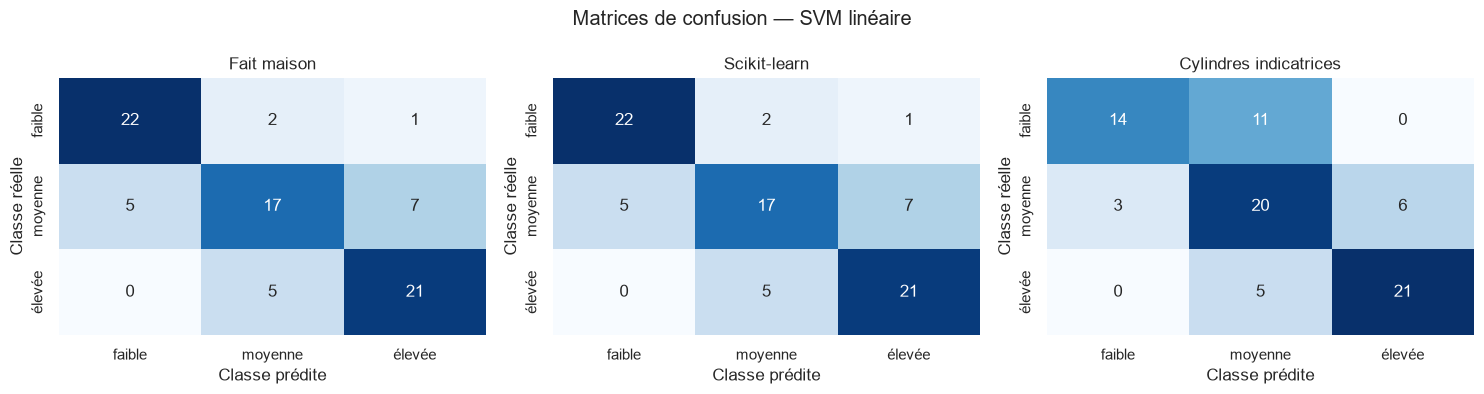

In [11]:
def mesurer_classification(nom, y_vrai, y_pred):
    return {
        "modèle": nom,
        "exactitude": accuracy_score(y_vrai, y_pred),
        "précision macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "rappel macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
    }


from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC

reference_lineaire = OneVsRestClassifier(SVC(C=C_lineaire_retenu, kernel="linear", decision_function_shape="ovr"))
reference_lineaire.fit(X_train, y_train_classes)
pred_reference_lineaire = reference_lineaire.predict(X_test)

resultats_lineaires = [
    mesurer_classification("SVM linéaire fait maison", y_test_classes, pred_lineaire),
    mesurer_classification("SVC linéaire scikit-learn (OvR)", y_test_classes, pred_reference_lineaire),
]

# Variante expérimentale : les cylindres sont codés en indicatrices; origin reste codée en indicatrices.
autres_numeriques = [v for v in VARIABLES_NUMERIQUES if v != "cylinders"]
standardiseur_alt = MyStandardScaler().fit(train[autres_numeriques])
origin_train_df, origin_test_df = encoder_origin(train), encoder_origin(test)
cyl_train_df = pd.get_dummies(train["cylinders"].astype(str), prefix="cylinders", dtype=float)
cyl_test_df = pd.get_dummies(test["cylinders"].astype(str), prefix="cylinders", dtype=float)
cyl_train_df, cyl_test_df = cyl_train_df.align(cyl_test_df, join="left", axis=1, fill_value=0)
X_train_alt_df = pd.concat([standardiseur_alt.transform(train[autres_numeriques]), cyl_train_df, origin_train_df], axis=1)
X_test_alt_df = pd.concat([standardiseur_alt.transform(test[autres_numeriques]), cyl_test_df, origin_test_df], axis=1)
modele_cyl_onehot = SVMLineaireOvR(C=C_lineaire_retenu, iterations=5000, taux=0.15).fit(
    X_train_alt_df.to_numpy(), y_train_classes
)
pred_cyl_onehot = modele_cyl_onehot.predict(X_test_alt_df.to_numpy())
resultats_lineaires.append(mesurer_classification("SVM linéaire, cylindres indicatrices", y_test_classes, pred_cyl_onehot))
table_lineaire = pd.DataFrame(resultats_lineaires)
display(table_lineaire)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nom, pred in zip(axes, ["Fait maison", "Scikit-learn", "Cylindres indicatrices"], [pred_lineaire, pred_reference_lineaire, pred_cyl_onehot]):
    sns.heatmap(confusion_matrix(y_test_classes, pred, labels=[0, 1, 2]), annot=True, fmt="d", cmap="Blues",
                xticklabels=NOMS_CLASSES, yticklabels=NOMS_CLASSES, ax=ax, cbar=False)
    ax.set_title(nom)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
fig.suptitle("Matrices de confusion — SVM linéaire")
fig.tight_layout()
plt.show()

### Lecture des résultats — représentation des cylindres

Le SVM linéaire avec le nombre de cylindres traité comme variable ordonnée obtient **0,750 d’exactitude et 0,750 de F1 macro** sur cette partition; la référence linéaire scikit-learn donne les mêmes scores. La matrice décrit les erreurs pour les trois classes quantiles.

La variante avec indicatrices `cylinders` obtient **0,688 d’exactitude et 0,692 de F1 macro**, en dessous de la représentation ordonnée sur ce test. Cela motive le maintien de l’encodage ordinal dans l’analyse principale, sans prouver une supériorité générale : cette comparaison dépend d’une seule partition et d’un réglage choisi par validation croisée.

## 13. SVM RBF non linéaire et SMO

Les relations mises en évidence par l’analyse exploratoire entre consommation, poids, cylindrée et puissance sont fortes mais courbes et dispersées; un hyperplan peut ne pas capturer les plateaux. RBF est donc comparé, sans supposer qu’il sera meilleur.

Le noyau gaussien $\exp(-\|x-z\|^2/(2s^2))$, avec $\gamma=\frac{1}{2s^2}$, devient

$$
K(x,z)=\exp(-\gamma\|x-z\|^2).
$$

Il vaut 1 pour deux vecteurs identiques et tend vers 0 quand ils s’éloignent. Une grande valeur de $\gamma$ rend l’influence locale et la frontière flexible; une petite valeur la lisse. Nous ajustons $C \in \{0{,}1;\,1;\,10\}$ et $\gamma \in \{\frac{0{,}5}{p};\,\frac{1}{p};\,\frac{2}{p}\}$ avec une validation croisée stratifiée à trois plis dans l’entraînement, en retenant le F1 macro moyen maximal. Le jeu de test ne participe pas à ce réglage.

La matrice de Gram contient tous les $K(x_i,x_j)$. SMO met à jour deux multiplicateurs sous contraintes de boîte et d’égalité; les multiplicateurs non nuls forment les supports. Notre heuristique et ses tolérances peuvent différer du solveur industriel de scikit-learn.

In [12]:
def noyau_rbf(X, Z, gamma):
    X = np.asarray(X, dtype=float)
    Z = np.asarray(Z, dtype=float)
    distances2 = np.maximum(0.0, (X * X).sum(axis=1)[:, None] + (Z * Z).sum(axis=1)[None, :] - 2 * X @ Z.T)
    return np.exp(-gamma * distances2)


class SVMNoyauBinaireSMO:
    def __init__(self, C=1.0, gamma=0.1, tolerance=1e-3, epsilon=1e-3, iterations_max=50000, passes_max=8):
        self.C, self.gamma = float(C), float(gamma)
        self.tolerance, self.epsilon = float(tolerance), float(epsilon)
        self.iterations_max, self.passes_max = int(iterations_max), int(passes_max)

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if self.X_train_.ndim != 2 or y.shape != (len(self.X_train_),) or set(np.unique(y)) != {-1.0, 1.0}:
            raise ValueError("X ou codage binaire y invalide.")
        n = len(y)
        K = noyau_rbf(self.X_train_, self.X_train_, self.gamma)
        alpha = np.zeros(n)
        b = 0.0
        erreurs = -y.copy()
        passes, etapes = 0, 0
        rng = np.random.default_rng(RANDOM_STATE)

        while passes < self.passes_max and etapes < self.iterations_max:
            changements = 0
            for i in rng.permutation(n):
                if etapes >= self.iterations_max:
                    break
                Ei = erreurs[i]
                yi, ai = y[i], alpha[i]
                viole = (yi * Ei < -self.tolerance and ai < self.C - self.epsilon) or (yi * Ei > self.tolerance and ai > self.epsilon)
                if not viole:
                    continue
                non_bornes = np.flatnonzero((alpha > self.epsilon) & (alpha < self.C - self.epsilon))
                candidats = np.setdiff1d(non_bornes if len(non_bornes) else np.arange(n), [i], assume_unique=False)
                if len(candidats) == 0:
                    continue
                candidats = candidats[np.argsort(-np.abs(Ei - erreurs[candidats]))]
                mise_a_jour = False
                for j in candidats[:min(30, len(candidats))]:
                    etapes += 1
                    Ej = erreurs[j]
                    yj, aj = y[j], alpha[j]
                    ai_old, aj_old, b_old = ai, aj, b
                    if yi != yj:
                        L, H = max(0.0, aj - ai), min(self.C, self.C + aj - ai)
                    else:
                        L, H = max(0.0, ai + aj - self.C), min(self.C, ai + aj)
                    if H - L < self.epsilon:
                        continue
                    eta = 2 * K[i, j] - K[i, i] - K[j, j]
                    if eta >= -1e-12:
                        continue
                    aj_new = aj - yj * (Ei - Ej) / eta
                    aj_new = float(np.clip(aj_new, L, H))
                    if abs(aj_new - aj_old) < self.epsilon * (aj_new + aj_old + self.epsilon):
                        continue
                    ai_new = ai + yi * yj * (aj_old - aj_new)
                    alpha[i], alpha[j] = ai_new, aj_new
                    b1 = b_old - Ei - yi * (ai_new - ai_old) * K[i, i] - yj * (aj_new - aj_old) * K[i, j]
                    b2 = b_old - Ej - yi * (ai_new - ai_old) * K[i, j] - yj * (aj_new - aj_old) * K[j, j]
                    if self.epsilon < ai_new < self.C - self.epsilon:
                        b = b1
                    elif self.epsilon < aj_new < self.C - self.epsilon:
                        b = b2
                    else:
                        b = 0.5 * (b1 + b2)
                    erreurs += yi * (ai_new - ai_old) * K[:, i] + yj * (aj_new - aj_old) * K[:, j] + (b - b_old)
                    changements += 1
                    mise_a_jour = True
                    break
                if mise_a_jour:
                    continue
            passes = passes + 1 if changements == 0 else 0

        self.alpha_ = alpha
        self.b_ = float(b)
        self.support_ = np.flatnonzero(alpha > self.epsilon)
        self.support_vectors_ = self.X_train_[self.support_]
        self.coef_support_ = alpha[self.support_] * y[self.support_]
        self.n_iter_ = etapes
        return self

    def decision_function(self, X):
        K = noyau_rbf(np.asarray(X, dtype=float), self.support_vectors_, self.gamma)
        return K @ self.coef_support_ + self.b_


class SVMRBF_OVR:
    def __init__(self, C=1.0, gamma=0.1):
        self.C, self.gamma = C, gamma

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.modeles_ = []
        for classe in self.classes_:
            cible = np.where(np.asarray(y) == classe, 1.0, -1.0)
            self.modeles_.append(SVMNoyauBinaireSMO(C=self.C, gamma=self.gamma).fit(X, cible))
        return self

    def decision_function(self, X):
        return np.column_stack([m.decision_function(X) for m in self.modeles_])

    def predict(self, X):
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]


C_GRILLE_RBF = [0.1, 1.0, 10.0]
gamma_base = 1.0 / X_train.shape[1]
GAMMA_GRILLE_RBF = [0.5 * gamma_base, gamma_base, 2.0 * gamma_base]
resultats_cv_rbf = []
for C_candidat in C_GRILLE_RBF:
    for gamma_candidat in GAMMA_GRILLE_RBF:
        scores = []
        for X_cv_apprentissage, X_cv_validation, y_cv_apprentissage, y_cv_validation, _, _ in plis_cv:
            modele_cv = SVMRBF_OVR(C=C_candidat, gamma=gamma_candidat).fit(X_cv_apprentissage, y_cv_apprentissage)
            scores.append(f1_score(y_cv_validation, modele_cv.predict(X_cv_validation), average="macro"))
        resultats_cv_rbf.append({
            "C": C_candidat, "gamma": gamma_candidat,
            "F1 macro moyen": np.mean(scores), "écart-type entre plis": np.std(scores, ddof=1),
        })
table_cv_rbf = pd.DataFrame(resultats_cv_rbf).sort_values(
    ["F1 macro moyen", "C", "gamma"], ascending=[False, True, True]
).reset_index(drop=True)
print("Validation croisée RBF, grille C × gamma et trois plis de l’entraînement :")
display(table_cv_rbf.round(4))
C_rbf_retenu = float(table_cv_rbf.iloc[0]["C"])
gamma_choisi = float(table_cv_rbf.iloc[0]["gamma"])
print("Réglages RBF sélectionnés sans consulter le test : C =", C_rbf_retenu, "; gamma =", gamma_choisi)
modele_rbf = SVMRBF_OVR(C=C_rbf_retenu, gamma=gamma_choisi).fit(X_train, y_train_classes)
pred_rbf = modele_rbf.predict(X_test)
print("gamma :", gamma_choisi)
print("Itérations SMO par classe :", [m.n_iter_ for m in modele_rbf.modeles_])
print("Vecteurs de support par classe :", [len(m.support_) for m in modele_rbf.modeles_])

Validation croisée RBF, grille C × gamma et trois plis de l’entraînement :


,C,gamma,F1 macro moyen,écart-type entre plis
0,1.0,0.2222,0.8429,0.0043
1,1.0,0.1111,0.8383,0.0192
2,10.0,0.2222,0.8325,0.0371
3,10.0,0.0556,0.8317,0.0103
4,10.0,0.1111,0.8274,0.0122
5,0.1,0.1111,0.8252,0.0206
6,0.1,0.2222,0.8213,0.0281
7,1.0,0.0556,0.8196,0.0165
8,0.1,0.0556,0.8033,0.0229


Réglages RBF sélectionnés sans consulter le test : C = 1.0 ; gamma = 0.2222222222222222
gamma : 0.2222222222222222
Itérations SMO par classe : [1314, 1171, 1443]
Vecteurs de support par classe : [80, 149, 107]


### Lecture des résultats — optimisation SMO

La grille retient **$C=1$** et $\gamma=\frac{2}{9}\approx0{,}2222$, dont le F1 macro moyen en validation croisée est **0,8429** (écart-type **0,0043** entre trois plis). Les multiplicateurs non nuls du modèle maison correspondent à **80, 149 et 107 vecteurs de support** pour les trois classes; SMO effectue respectivement 1 314, 1 171 et 1 443 tentatives dans les ajustements finaux.

Le nombre de supports décrit la représentation de la frontière, pas la performance. La validation de trois plis renseigne sur le réglage des paramètres dans l’entraînement; la comparaison sur le test tenu à l’écart peut donner un classement différent.


## 14. Évaluation finale de la classification

Les quatre classifieurs utilisent les mêmes matrices, seuils, lignes et stratégie un-contre-tous. Le tableau de métriques macro est complété par des matrices de confusion et des nombres de supports. Des scores identiques à l’arrondi indiquent une forte concordance sur cette partition; ils ne prouvent ni identité des optimiseurs ni généralisation universelle.

,modèle,exactitude,précision macro,rappel macro,F1 macro
0,SVM linéaire fait maison,0.7500,0.749095,0.757966,0.750433
1,SVC linéaire scikit-learn (OvR),0.7500,0.749095,0.757966,0.750433
2,"SVM RBF fait maison (SMO, OvR)",0.7375,0.745733,0.740955,0.742729
3,SVC RBF scikit-learn (OvR),0.7375,0.745733,0.740955,0.742729


Lecture : les métriques macro accordent le même poids aux trois classes; comparer les indicateurs avant de conclure sur un modèle.
Vecteurs de support RBF scikit-learn par classe : [80, 149, 107]
Classification avec seuils à largeur égale (réglages issus de la validation croisée quantile) :


,modèle,exactitude,précision macro,rappel macro,F1 macro,discrétisation
0,SVM linéaire maison,0.8625,0.909524,0.730952,0.762240,largeur égale
1,SVC linéaire scikit-learn,0.8875,0.922619,0.805026,0.841288,largeur égale
2,SVM RBF maison,0.8750,0.843565,0.823016,0.832190,largeur égale
3,SVC RBF scikit-learn,0.8750,0.843565,0.823016,0.832190,largeur égale


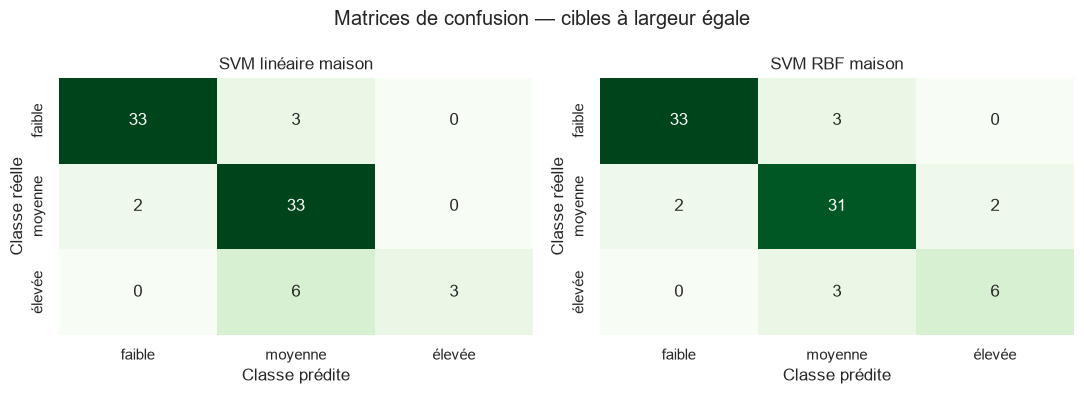

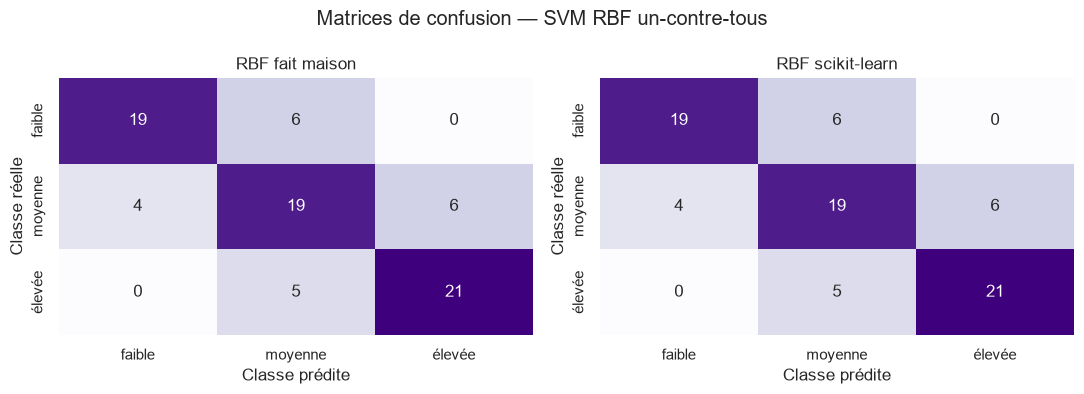

In [13]:
reference_rbf = OneVsRestClassifier(SVC(C=C_rbf_retenu, kernel="rbf", gamma=gamma_choisi, decision_function_shape="ovr"))
reference_rbf.fit(X_train, y_train_classes)
pred_reference_rbf = reference_rbf.predict(X_test)
resultats_classification = pd.DataFrame([
    mesurer_classification("SVM linéaire fait maison", y_test_classes, pred_lineaire),
    mesurer_classification("SVC linéaire scikit-learn (OvR)", y_test_classes, pred_reference_lineaire),
    mesurer_classification("SVM RBF fait maison (SMO, OvR)", y_test_classes, pred_rbf),
    mesurer_classification("SVC RBF scikit-learn (OvR)", y_test_classes, pred_reference_rbf),
])
display(resultats_classification)
print("Lecture : les métriques macro accordent le même poids aux trois classes; comparer les indicateurs avant de conclure sur un modèle.")
print("Vecteurs de support RBF scikit-learn par classe :", [len(m.support_) for m in reference_rbf.estimators_])

# Sensibilité à la discrétisation : mêmes matrices et paramètres sélectionnés sur les plis quantiles.
modele_lineaire_largeur = SVMLineaireOvR(C=C_lineaire_retenu, iterations=5000, taux=0.15).fit(X_train, y_train_largeur)
pred_lineaire_largeur = modele_lineaire_largeur.predict(X_test)
reference_lineaire_largeur = OneVsRestClassifier(SVC(C=C_lineaire_retenu, kernel="linear", decision_function_shape="ovr"))
reference_lineaire_largeur.fit(X_train, y_train_largeur)
pred_reference_lineaire_largeur = reference_lineaire_largeur.predict(X_test)
modele_rbf_largeur = SVMRBF_OVR(C=C_rbf_retenu, gamma=gamma_choisi).fit(X_train, y_train_largeur)
pred_rbf_largeur = modele_rbf_largeur.predict(X_test)
reference_rbf_largeur = OneVsRestClassifier(SVC(C=C_rbf_retenu, kernel="rbf", gamma=gamma_choisi, decision_function_shape="ovr"))
reference_rbf_largeur.fit(X_train, y_train_largeur)
pred_reference_rbf_largeur = reference_rbf_largeur.predict(X_test)
resultats_largeur = []
for nom, prediction in [
    ("SVM linéaire maison", pred_lineaire_largeur),
    ("SVC linéaire scikit-learn", pred_reference_lineaire_largeur),
    ("SVM RBF maison", pred_rbf_largeur),
    ("SVC RBF scikit-learn", pred_reference_rbf_largeur),
]:
    ligne = mesurer_classification(nom, y_test_largeur, prediction)
    ligne["discrétisation"] = "largeur égale"
    resultats_largeur.append(ligne)
tableau_largeur = pd.DataFrame(resultats_largeur)
print("Classification avec seuils à largeur égale (réglages issus de la validation croisée quantile) :")
display(tableau_largeur)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nom, prediction in zip(
    axes, ["SVM linéaire maison", "SVM RBF maison"], [pred_lineaire_largeur, pred_rbf_largeur]
):
    sns.heatmap(confusion_matrix(y_test_largeur, prediction, labels=[0, 1, 2]), annot=True, fmt="d", cmap="Greens",
                xticklabels=NOMS_CLASSES, yticklabels=NOMS_CLASSES, ax=ax, cbar=False)
    ax.set_title(nom)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
fig.suptitle("Matrices de confusion — cibles à largeur égale")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nom, pred in zip(axes, ["RBF fait maison", "RBF scikit-learn"], [pred_rbf, pred_reference_rbf]):
    sns.heatmap(confusion_matrix(y_test_classes, pred, labels=[0, 1, 2]), annot=True, fmt="d", cmap="Purples",
                xticklabels=NOMS_CLASSES, yticklabels=NOMS_CLASSES, ax=ax, cbar=False)
    ax.set_title(nom)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
fig.suptitle("Matrices de confusion — SVM RBF un-contre-tous")
fig.tight_layout()
plt.show()

### Lecture des résultats — comparaison linéaire/RBF et discrétisations

Avec les classes par quantiles, le SVM linéaire maison obtient **0,750 d’exactitude et 0,750 de F1 macro** sur le test; le RBF obtient **0,738 et 0,743**. La validation croisée a favorisé le RBF en moyenne (0,843 contre 0,813 pour le linéaire), mais cette partition tenue à l’écart ne montre pas de gain du RBF. L’écart de test est faible et ne justifie pas un classement général à partir de 80 observations.

La comparaison à largeur égale donne un résultat différent. Le SVC linéaire scikit-learn atteint **0,888 d’exactitude et 0,841 de F1 macro**, tandis que la version maison atteint 0,863 et 0,762. Les deux RBF obtiennent **0,875 d’exactitude et 0,832 de F1 macro**. La discrétisation change donc la difficulté et les erreurs par classe; les scores quantiles ne suffisent pas à résumer les performances de classification.

Pour RBF, les prédictions maison et scikit-learn coïncident sur ce test avec les paramètres retenus. Cela vérifie une concordance empirique de cette exécution, sans établir l’équivalence des optimiseurs ni une performance universelle.


## 15. Fondements mathématiques du SVR linéaire

Le SVC prédit une classe, tandis que le SVR prédit une valeur réelle; nous conservons donc la cible continue `mpg`. La perte $\epsilon$-insensible est

$$
L_\varepsilon(y,f(x))=\max(0,|y-f(x)|-\varepsilon).
$$

Entre $f(x)-\varepsilon$ et $f(x)+\varepsilon$, l’erreur n’ajoute pas de perte : c’est le tube. L’objectif primal $\frac12\|w\|^2+C\sum_iL_\varepsilon$ équilibre simplicité et résidus hors du tube; $C$ règle leur pénalité, $\epsilon$ la tolérance en mpg.

Le dual linéaire pose $\beta_i=\alpha_i-\alpha_i^*$. Notre solveur minimise le problème convexe suivant :

$$
\min_{\boldsymbol{\beta}}\; \frac{1}{2}\boldsymbol{\beta}^{\top}K\boldsymbol{\beta}
-\mathbf{y}^{\top}\boldsymbol{\beta}
+\epsilon\sum_{i=1}^{n}|\beta_i|,
\qquad \sum_{i=1}^{n}\beta_i=0,
\qquad -C\leq\beta_i\leq C.
$$

Le gradient proximal accéléré utilise la matrice de Gram $K=XX^\top$. La dichotomie dans le prox impose la contrainte de somme nulle en plus du seuillage et des bornes. Le biais est récupéré à partir des supports libres. Un support est défini par un coefficient dual non nul, pas seulement par une observation hors du tube.

## 16. SVR fait maison, expériences sur $\epsilon$ et comparaison

Les valeurs $\varepsilon\in\{0{,}1,0{,}5,1,2\}$ sont en mpg. Une grille $C \in \{0{,}1;\,1;\,10\} \times \epsilon$ est évaluée par validation croisée stratifiée à trois plis dans l’entraînement selon la RMSE moyenne; ensuite, le $C$ retenu est conservé pour comparer l’effet propre d’$\epsilon$ sur les mêmes données de test. Pour chaque valeur, nous rapportons MAE et RMSE en mpg, MSE en mpg², $R^2$, nombre de coefficients duals non nuls et convergence. La référence `SVR(kernel="linear")` reçoit le même $C$ retenu, $\epsilon$, entrées et partition; elle expose aussi les supports.

Les plis stratifiés recalculent les imputations et les scalers à partir des seules lignes d’apprentissage. Le test n’intervient ni dans le choix des réglages ni dans le calcul CV.

Pour le SVR propre, le $C$ retenu est conservé et $\epsilon$ varie afin d’isoler son influence. Le solveur maison minimise le dual par gradient proximal accéléré. La contrainte de somme nulle est imposée dans le prox par dichotomie; le critère d’arrêt porte sur la norme du gradient proximal, avec tolérance $10^{-2}$ et un maximum de 10 000 itérations. L’état et le nombre d’itérations sont rapportés. La référence linéaire scikit-learn reçoit la même tolérance et un budget maximal de 100 000 itérations.

Validation croisée SVR, grille C × epsilon et trois plis d’entraînement :


,C,epsilon,RMSE moyenne,écart-type RMSE,taux de convergence
0,10.0,2.0,3.4421,0.7299,1.0
1,10.0,1.0,3.4659,0.8206,1.0
2,1.0,2.0,3.4688,0.7712,1.0
3,1.0,1.0,3.5025,0.8480,1.0
4,1.0,0.5,3.5394,0.9022,1.0
5,10.0,0.5,3.5457,0.8980,1.0
6,1.0,0.1,3.5542,0.9366,1.0
7,10.0,0.1,3.5579,0.9120,1.0
8,0.1,0.5,3.5846,0.8205,1.0
9,0.1,1.0,3.6075,0.8151,1.0


Réglages SVR retenus par RMSE moyenne, sans consulter le test : C = 10.0 ; epsilon = 2.0


,modèle,epsilon,MAE,MSE,RMSE,R2,vecteurs de support,itérations,variation finale,convergence
0,SVR fait maison,0.1,2.592438,11.434881,3.381550,0.787733,314,2709.0,0.256848,True
1,SVR linéaire scikit-learn,0.1,2.599286,11.518296,3.393861,0.786184,309,NaN,NaN,NaN
2,SVR fait maison,0.5,2.602110,11.612677,3.407738,0.784432,271,3866.0,0.256545,True
3,SVR linéaire scikit-learn,0.5,2.604999,11.643391,3.412241,0.783862,268,NaN,NaN,NaN
4,SVR fait maison,1.0,2.562071,11.157805,3.340330,0.792876,222,2013.0,0.255791,True
5,SVR linéaire scikit-learn,1.0,2.560556,11.128588,3.335954,0.793419,222,NaN,NaN,NaN
6,SVR fait maison,2.0,2.452821,9.885096,3.144057,0.816502,159,3939.0,0.201976,True
7,SVR linéaire scikit-learn,2.0,2.451639,9.889613,3.144775,0.816418,156,NaN,NaN,NaN


Lecture des supports : leur nombre diminue avec epsilon dans cette expérience.


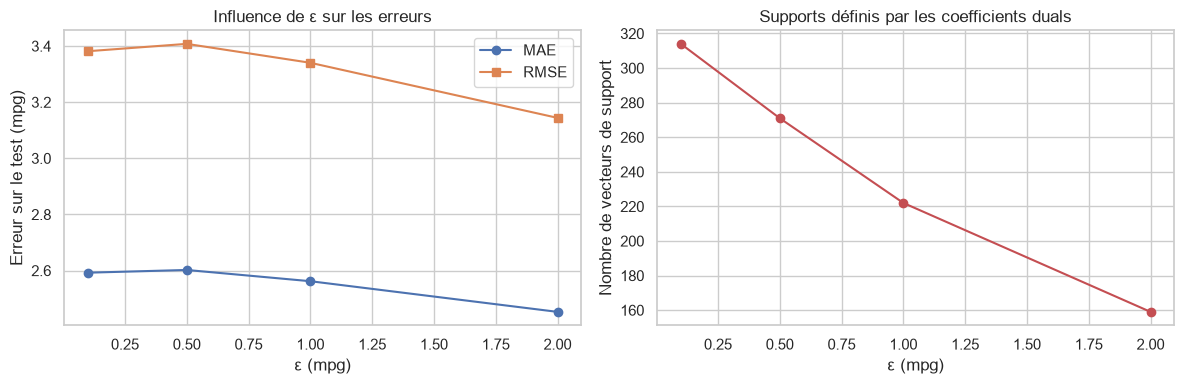

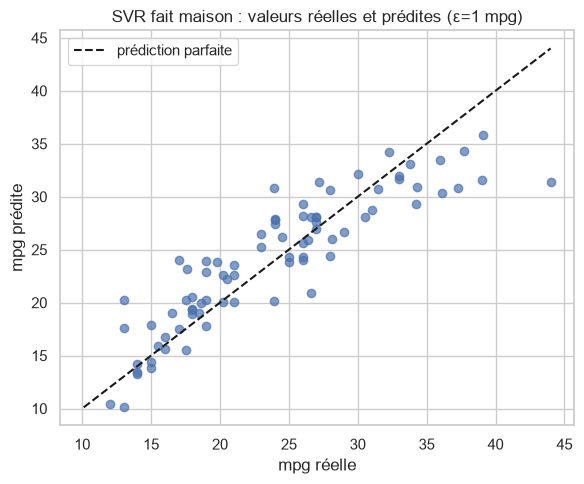

In [14]:
class SVRLineaireFaitMaison:
    """SVR linéaire dual résolu par gradient proximal accéléré, sans optimiseur externe."""
    def __init__(self, C=1.0, epsilon=0.1, tolerance=1e-3, iterations_max=1000, support_tolerance=1e-5):
        if C <= 0 or epsilon < 0 or iterations_max < 1 or tolerance <= 0:
            raise ValueError("C, la tolérance et le budget doivent être positifs; epsilon doit être non négatif.")
        self.C, self.epsilon = float(C), float(epsilon)
        self.tolerance, self.iterations_max = float(tolerance), int(iterations_max)
        self.support_tolerance = float(support_tolerance)

    def _prox_dual(self, v, seuil_epsilon):
        # Prox de epsilon*||beta||_1 + indicatrice{|beta_i|<=C, somme(beta)=0}.
        # Le multiplicateur de la contrainte d’égalité est trouvé par dichotomie.
        bas = float(np.min(v) - self.C - seuil_epsilon - 1.0)
        haut = float(np.max(v) + self.C + seuil_epsilon + 1.0)
        for _ in range(60):
            multiplicateur = 0.5 * (bas + haut)
            decale = v - multiplicateur
            beta = np.sign(decale) * np.maximum(np.abs(decale) - seuil_epsilon, 0.0)
            beta = np.clip(beta, -self.C, self.C)
            if beta.sum() > 0.0:
                bas = multiplicateur
            else:
                haut = multiplicateur
        multiplicateur = 0.5 * (bas + haut)
        decale = v - multiplicateur
        beta = np.sign(decale) * np.maximum(np.abs(decale) - seuil_epsilon, 0.0)
        return np.clip(beta, -self.C, self.C)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (len(X),) or len(y) < 2:
            raise ValueError("X et y ont des dimensions incompatibles.")
        K = X @ X.T
        valeur_propre_max = float(np.linalg.eigvalsh(K)[-1])
        pas = 1.0 / max(valeur_propre_max, 1e-12)
        beta = np.zeros(len(y), dtype=float)
        extrapole = beta.copy()
        facteur_acceleration = 1.0
        echelle = 1.0 + np.linalg.norm(y) / np.sqrt(len(y))
        self.converged_ = False
        self.variation_finale_ = np.inf

        for iteration in range(self.iterations_max):
            gradient = K @ extrapole - y
            beta_suivant = self._prox_dual(extrapole - pas * gradient, pas * self.epsilon)
            variation = float(np.linalg.norm(beta_suivant - beta))
            self.variation_finale_ = variation / pas / np.sqrt(len(y))

            facteur_suivant = 0.5 * (1.0 + np.sqrt(1.0 + 4.0 * facteur_acceleration ** 2))
            extrapole = beta_suivant + ((facteur_acceleration - 1.0) / facteur_suivant) * (beta_suivant - beta)
            beta = beta_suivant
            facteur_acceleration = facteur_suivant
            if self.variation_finale_ <= self.tolerance * echelle:
                self.converged_ = True
                break

        self.beta_ = beta
        self.n_iter_ = iteration + 1
        self.n_sweeps_ = self.n_iter_  # nom conservé pour compatibilité avec les tableaux déjà définis
        self.w_ = X.T @ beta
        supports = np.flatnonzero(np.abs(beta) > self.support_tolerance)
        libres = np.flatnonzero((np.abs(beta) > self.support_tolerance) & (np.abs(beta) < self.C - self.support_tolerance))
        indices_biais = libres if len(libres) else supports
        if len(indices_biais):
            predictions_sans_biais = X @ self.w_
            valeurs_biais = [
                y[i] - predictions_sans_biais[i] - self.epsilon if beta[i] > 0
                else y[i] - predictions_sans_biais[i] + self.epsilon
                for i in indices_biais
            ]
            self.b_ = float(np.median(valeurs_biais))
        else:
            self.b_ = float(np.median(y))
        self.support_ = supports
        self.n_support_ = len(supports)
        self.objectif_dual_ = float(0.5 * beta @ K @ beta - y @ beta + self.epsilon * np.abs(beta).sum())
        self.somme_beta_ = float(beta.sum())
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_


# Sélection de C et epsilon par RMSE moyenne sur les mêmes trois plis d’entraînement.
valeurs_epsilon = [0.1, 0.5, 1.0, 2.0]
TOLERANCE_SVR = 1e-2
ITERATIONS_MAX_SVR = 10000
C_GRILLE_SVR = [0.1, 1.0, 10.0]
resultats_cv_svr = []
for C_candidat in C_GRILLE_SVR:
    for epsilon_candidat in valeurs_epsilon:
        erreurs_cv = []
        convergences_cv = []
        for X_cv_apprentissage, X_cv_validation, _, _, y_cv_apprentissage, y_cv_validation in plis_cv:
            modele_cv = SVRLineaireFaitMaison(
                C=C_candidat, epsilon=epsilon_candidat, tolerance=TOLERANCE_SVR, iterations_max=ITERATIONS_MAX_SVR
            ).fit(X_cv_apprentissage, y_cv_apprentissage)
            prediction_cv = modele_cv.predict(X_cv_validation)
            erreurs_cv.append(np.sqrt(mean_squared_error(y_cv_validation, prediction_cv)))
            convergences_cv.append(modele_cv.converged_)
        resultats_cv_svr.append({
            "C": C_candidat, "epsilon": epsilon_candidat,
            "RMSE moyenne": np.mean(erreurs_cv), "écart-type RMSE": np.std(erreurs_cv, ddof=1),
            "taux de convergence": np.mean(convergences_cv),
        })

table_cv_svr = pd.DataFrame(resultats_cv_svr).sort_values(
    ["RMSE moyenne", "C", "epsilon"], ascending=[True, True, True]
).reset_index(drop=True)
print("Validation croisée SVR, grille C × epsilon et trois plis d’entraînement :")
display(table_cv_svr.round(4))
C_svr_retenu = float(table_cv_svr.iloc[0]["C"])
epsilon_svr_retenu = float(table_cv_svr.iloc[0]["epsilon"])
print("Réglages SVR retenus par RMSE moyenne, sans consulter le test : C =", C_svr_retenu, "; epsilon =", epsilon_svr_retenu)

resultats_svr = []
predictions_svr = {}
for epsilon in valeurs_epsilon:
    modele_maison = SVRLineaireFaitMaison(C=C_svr_retenu, epsilon=epsilon, tolerance=TOLERANCE_SVR, iterations_max=ITERATIONS_MAX_SVR).fit(X_train, y_mpg_train)
    pred_maison = modele_maison.predict(X_test)
    predictions_svr[("maison", epsilon)] = pred_maison
    resultats_svr.append({
        "modèle": "SVR fait maison", "epsilon": epsilon,
        "MAE": mean_absolute_error(y_mpg_test, pred_maison),
        "MSE": mean_squared_error(y_mpg_test, pred_maison),
        "RMSE": np.sqrt(mean_squared_error(y_mpg_test, pred_maison)),
        "R2": r2_score(y_mpg_test, pred_maison),
        "vecteurs de support": modele_maison.n_support_,
        "itérations": modele_maison.n_sweeps_,
        "variation finale": modele_maison.variation_finale_,
        "convergence": modele_maison.converged_,
    })

    from sklearn.svm import SVR
    modele_reference = SVR(kernel="linear", C=C_svr_retenu, epsilon=epsilon, tol=TOLERANCE_SVR, max_iter=100000)
    modele_reference.fit(X_train, y_mpg_train)
    pred_reference = modele_reference.predict(X_test)
    predictions_svr[("scikit-learn", epsilon)] = pred_reference
    resultats_svr.append({
        "modèle": "SVR linéaire scikit-learn", "epsilon": epsilon,
        "MAE": mean_absolute_error(y_mpg_test, pred_reference),
        "MSE": mean_squared_error(y_mpg_test, pred_reference),
        "RMSE": np.sqrt(mean_squared_error(y_mpg_test, pred_reference)),
        "R2": r2_score(y_mpg_test, pred_reference),
        "vecteurs de support": len(modele_reference.support_),
        "itérations": np.nan,
        "variation finale": np.nan,
        "convergence": np.nan,
    })

table_svr = pd.DataFrame(resultats_svr)
display(table_svr)

maison = table_svr[table_svr["modèle"] == "SVR fait maison"]
print("Lecture des supports :", "leur nombre diminue avec epsilon dans cette expérience." if maison["vecteurs de support"].is_monotonic_decreasing else "le nombre de supports ne diminue pas strictement à chaque valeur de epsilon dans cette expérience.")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(maison["epsilon"], maison["MAE"], marker="o", label="MAE")
axes[0].plot(maison["epsilon"], maison["RMSE"], marker="s", label="RMSE")
axes[0].set_xlabel("ε (mpg)")
axes[0].set_ylabel("Erreur sur le test (mpg)")
axes[0].set_title("Influence de ε sur les erreurs")
axes[0].legend()
axes[1].plot(maison["epsilon"], maison["vecteurs de support"], marker="o", color="#C44E52")
axes[1].set_xlabel("ε (mpg)")
axes[1].set_ylabel("Nombre de vecteurs de support")
axes[1].set_title("Supports définis par les coefficients duals")
fig.tight_layout()
plt.show()

epsilon_illustration = 1.0
pred_illustration = predictions_svr[("maison", epsilon_illustration)]
plt.figure(figsize=(6, 5))
plt.scatter(y_mpg_test, pred_illustration, alpha=0.7)
limites = [min(y_mpg_test.min(), pred_illustration.min()), max(y_mpg_test.max(), pred_illustration.max())]
plt.plot(limites, limites, "k--", label="prédiction parfaite")
plt.xlabel("mpg réelle")
plt.ylabel("mpg prédite")
plt.title("SVR fait maison : valeurs réelles et prédites (ε=1 mpg)")
plt.legend()
plt.tight_layout()
plt.show()

### Lecture des résultats — epsilon, vecteurs de support et prédictions

La validation croisée de la grille $C \times \epsilon$ retient **$C=10$** et **$\epsilon=2$ mpg** (RMSE moyenne **3,442 mpg**, écart-type **0,730** entre les trois plis). Les quatre valeurs de $\epsilon$ convergent dans les plis. Sur le test propre, le modèle maison converge également pour chacune, entre **2 013 et 3 939 itérations**; aucune alerte de convergence scikit-learn n’est émise avec la tolérance et le budget spécifiés.

Les nombres de supports maison sont **314, 271, 222 et 159** pour $\epsilon\in\{0{,}1;\,0{,}5;\,1;\,2\}$ mpg. Les RMSE correspondantes sont **3,382; 3,408; 3,340 et 3,144 mpg**. Elles ne varient pas de façon monotone, mais $\epsilon=2$ donne la plus faible erreur de cette grille. Les métriques sont proches de la référence SVR linéaire scikit-learn; les objectifs d’optimisation et les critères d’arrêt restent distincts.

Le nombre de supports diminue ici avec $\epsilon$, ce qui décrit une représentation plus parcimonieuse; cela ne prouve pas, à lui seul, une meilleure robustesse ou une meilleure généralisation.


## 17. Étude expérimentale de la robustesse au bruit et de l’influence de $\epsilon$

L’expérience précédente fait varier $\epsilon$, mais entraîne toujours les modèles sur les cibles MPG propres. Elle renseigne donc sur les performances et le nombre de vecteurs de support en données propres; elle ne mesure pas directement la tolérance au bruit des observations d’apprentissage.

En régression, le bruit de cible représente une perturbation de la mesure de `mpg`. La perte $\epsilon$-insensible

$$
L_\varepsilon(y,f(x))=\max(0,|y-f(x)|-\varepsilon)
$$

ne pénalise pas les résidus à l’intérieur du tube de largeur $2\varepsilon$. Nous allons vérifier si ce mécanisme limite l’influence de petites perturbations aléatoires sur l’ajustement, sans supposer qu’un $\epsilon$ plus grand améliorera toujours les prédictions.

Pour isoler cette question, nous ajoutons uniquement au vecteur de cibles d’entraînement un bruit gaussien additif :

$$
y^{(r,\sigma)}_{i,\mathrm{bruité}}=y_{i,\mathrm{entraînement}}+\sigma z^{(r)}_i,
\qquad z^{(r)}_i\sim\mathcal N(0,1).
$$

Ainsi, $\sigma$ est l’écart-type du bruit, exprimé en mpg. Un bruit gaussien centré est un modèle contrôlé simple d’erreurs de mesure indépendantes, sans biais moyen; il permet d’augmenter graduellement leur amplitude. Il ne représente toutefois ni les erreurs systématiques, ni un bruit dont la variance dépend du véhicule, ni toutes les anomalies réelles.

Nous comparerons $\sigma\in\{0;0{,}5;1;2;4\}$ mpg et les quatre valeurs de $\epsilon$ déjà étudiées, avec $C=C_{\mathrm{CV}}$. Cinq graines fixes produiront cinq vecteurs gaussiens indépendants. Pour une même répétition, le vecteur normalisé sera mis à l’échelle par chaque $\sigma$ et réutilisé pour chaque $\epsilon$ : cette comparaison appariée évite que les modèles comparés reçoivent des perturbations différentes. À $\sigma=0$, les cinq ajustements reproduisent le cas propre.

Seules les cibles d’entraînement seront perturbées. Les matrices $X_{\mathrm{train}}$ et $X_{\mathrm{test}}$, le vecteur des cibles propres d’entraînement et surtout $y_{\mathrm{test}}$ resteront inchangés. Toutes les prédictions seront évaluées contre les cibles de test propres. Cela mesure la généralisation vers des observations propres après un apprentissage bruité, et évite de masquer l’erreur par l’ajout du même bruit aux étiquettes d’évaluation.

Pour chaque répétition, niveau de bruit et $\epsilon$, nous enregistrerons MAE (erreur absolue moyenne), MSE et RMSE (erreurs quadratiques, cette dernière dans l’unité mpg), $R^2$ (variance expliquée), le nombre de vecteurs de support donné par les coefficients duaux du modèle, et l’état de convergence. Nous présenterons moyennes et écarts-types entre répétitions. Le nombre de supports décrira la complexité, mais la robustesse sera jugée d’abord par l’évolution des erreurs sur le test propre. Le solveur maison reste l’implémentation principale; la référence scikit-learn recevra les mêmes cibles bruitées et les mêmes réglages $C$, $\epsilon$ et noyau linéaire, tout en conservant ses critères d’arrêt propres.

Vérifications : X_train, X_test, y_mpg_train et y_mpg_test sont inchangés; toutes les évaluations utilisent y_test propre.
Répétitions par combinaison : 5 ; ajustements maison : 100
Ajustements scikit-learn de référence : 100
Résumé : moyennes et écarts-types échantillonnaux (ddof=1) sur les répétitions.


,modèle,sigma,epsilon,MAE_moyenne,MSE_moyenne,RMSE_moyenne,R2_moyenne,vecteurs de support_moyenne,itérations_moyenne,MAE_ecart_type,MSE_ecart_type,RMSE_ecart_type,R2_ecart_type,vecteurs de support_ecart_type,itérations_ecart_type,taux_convergence,repetitions
0,Référence scikit-learn,0.0,0.1,2.5993,11.5183,3.3939,0.7862,309.0,3097.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,5
1,Référence scikit-learn,0.0,0.5,2.6050,11.6434,3.4122,0.7839,268.0,6253.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,5
2,Référence scikit-learn,0.0,1.0,2.5606,11.1286,3.3360,0.7934,222.0,3452.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,5
3,Référence scikit-learn,0.0,2.0,2.4516,9.8896,3.1448,0.8164,156.0,4458.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,5
4,Référence scikit-learn,0.5,0.1,2.5849,11.5105,3.3926,0.7863,309.2,6066.0,0.0219,0.2061,0.0303,0.0038,1.9235,1487.4880,1.0,5
5,Référence scikit-learn,0.5,0.5,2.5987,11.6505,3.4129,0.7837,269.4,4784.2,0.0341,0.3818,0.0560,0.0071,5.4129,994.7066,1.0,5
6,Référence scikit-learn,0.5,1.0,2.5476,11.0107,3.3182,0.7956,229.8,4377.8,0.0258,0.1772,0.0268,0.0033,5.0200,1267.6974,1.0,5
7,Référence scikit-learn,0.5,2.0,2.4646,10.0005,3.1623,0.8144,160.4,3684.6,0.0150,0.1004,0.0159,0.0019,6.2690,861.4980,1.0,5
8,Référence scikit-learn,1.0,0.1,2.5730,11.3920,3.3746,0.7885,309.6,5791.8,0.0463,0.4731,0.0699,0.0088,2.7019,2057.2797,1.0,5
9,Référence scikit-learn,1.0,0.5,2.5577,11.1876,3.3440,0.7923,274.4,4576.0,0.0510,0.5407,0.0816,0.0100,5.0299,801.1426,1.0,5


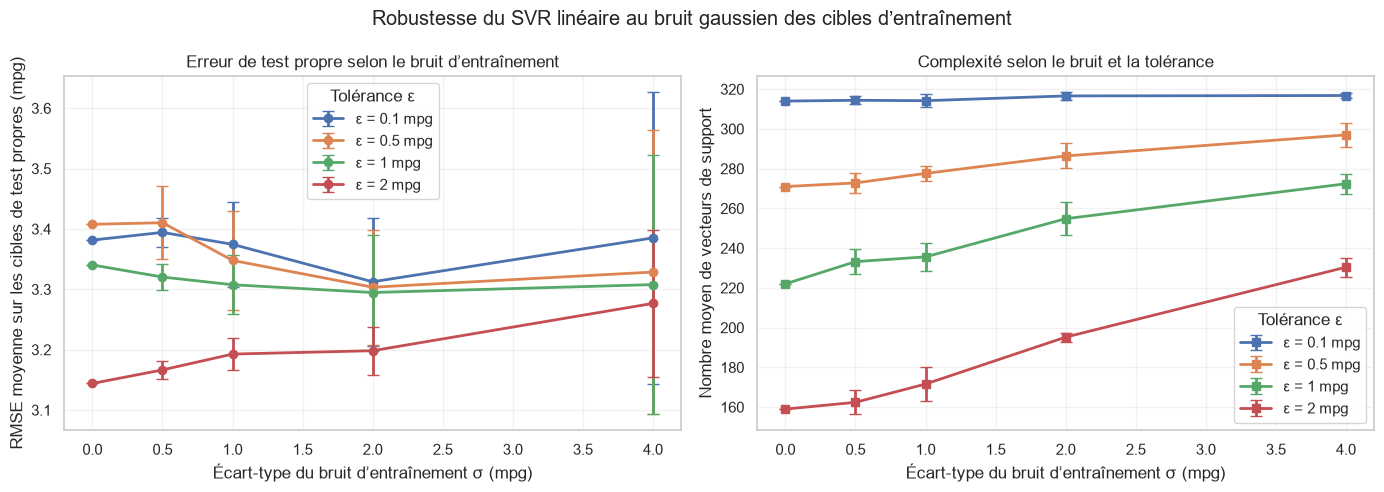

RMSE maison moyenne à sigma=0 et sigma=4, puis hausse observée :


sigma,RMSE sigma=0,RMSE sigma=4,hausse_RMSE
epsilon,,,
0.1,3.3816,3.3852,0.0037
0.5,3.4077,3.3286,-0.0791
1.0,3.3403,3.3078,-0.0325
2.0,3.1441,3.2767,0.1326


In [15]:
# Étude répétée : seules les cibles d’entraînement reçoivent du bruit.
niveaux_bruit = [0.0, 0.5, 1.0, 2.0, 4.0]  # écart-type en mpg
graines_bruit = [2026, 2027, 2028, 2029, 2030]
C_EXPERIENCE_BRUIT = C_svr_retenu

# Copies témoins : elles permettent de vérifier qu’aucune donnée propre n’a été modifiée.
X_train_propre_avant = X_train.copy()
X_test_propre_avant = X_test.copy()
y_train_propre_avant = y_mpg_train.copy()
y_test_propre_avant = y_mpg_test.copy()

# Un vecteur normal indépendant par répétition; il est partagé entre les niveaux de bruit
# après multiplication par sigma et entre les valeurs de epsilon pour une comparaison appariée.
bruits_normaux_par_graine = {
    graine: np.random.default_rng(graine).standard_normal(size=len(y_train_propre_avant))
    for graine in graines_bruit
}
assert all(
    np.array_equal(bruits_normaux_par_graine[g], np.random.default_rng(g).standard_normal(len(y_train_propre_avant)))
    for g in graines_bruit
), "La génération des perturbations n’est pas reproductible."

from sklearn.svm import SVR

lignes_experience_bruit = []
for sigma in niveaux_bruit:
    for graine in graines_bruit:
        y_train_bruite = y_train_propre_avant + sigma * bruits_normaux_par_graine[graine]
        for epsilon in valeurs_epsilon:
            # Notre solveur maison reste la méthode principale de l’expérience.
            modele_bruit_maison = SVRLineaireFaitMaison(
                C=C_EXPERIENCE_BRUIT, epsilon=epsilon, tolerance=TOLERANCE_SVR, iterations_max=ITERATIONS_MAX_SVR
            ).fit(X_train, y_train_bruite)
            prediction_maison = modele_bruit_maison.predict(X_test)
            lignes_experience_bruit.append({
                "modèle": "SVR maison",
                "sigma": sigma,
                "epsilon": epsilon,
                "graine": graine,
                "MAE": mean_absolute_error(y_test_propre_avant, prediction_maison),
                "MSE": mean_squared_error(y_test_propre_avant, prediction_maison),
                "RMSE": np.sqrt(mean_squared_error(y_test_propre_avant, prediction_maison)),
                "R2": r2_score(y_test_propre_avant, prediction_maison),
                "vecteurs de support": modele_bruit_maison.n_support_,
                "convergence": modele_bruit_maison.converged_,
                "itérations": modele_bruit_maison.n_sweeps_,
            })

            # Référence scikit-learn : même X, cible bruitée, C, epsilon et noyau linéaire.
            # Le comparateur reçoit une tolérance explicite et un budget accru pour limiter les arrêts prématurés.
            modele_bruit_reference = SVR(
                kernel="linear", C=C_EXPERIENCE_BRUIT, epsilon=epsilon, tol=TOLERANCE_SVR, max_iter=100000
            ).fit(X_train, y_train_bruite)
            prediction_reference = modele_bruit_reference.predict(X_test)
            lignes_experience_bruit.append({
                "modèle": "Référence scikit-learn",
                "sigma": sigma,
                "epsilon": epsilon,
                "graine": graine,
                "MAE": mean_absolute_error(y_test_propre_avant, prediction_reference),
                "MSE": mean_squared_error(y_test_propre_avant, prediction_reference),
                "RMSE": np.sqrt(mean_squared_error(y_test_propre_avant, prediction_reference)),
                "R2": r2_score(y_test_propre_avant, prediction_reference),
                "vecteurs de support": len(modele_bruit_reference.support_),
                "convergence": modele_bruit_reference.fit_status_ == 0,
                "itérations": modele_bruit_reference.n_iter_,
            })

resultats_bruit_detail = pd.DataFrame(lignes_experience_bruit)
mesures_a_agreger = ["MAE", "MSE", "RMSE", "R2", "vecteurs de support", "itérations"]
resume_bruit = (
    resultats_bruit_detail
    .groupby(["modèle", "sigma", "epsilon"], sort=True)
    .agg(
        **{f"{m}_moyenne": (m, "mean") for m in mesures_a_agreger},
        **{f"{m}_ecart_type": (m, "std") for m in mesures_a_agreger},
        taux_convergence=("convergence", "mean"),
        repetitions=("graine", "count"),
    )
    .reset_index()
)

# Les cinq répétitions sigma=0 doivent retrouver les résultats propres de l’expérience précédente.
for epsilon in valeurs_epsilon:
    resultat_propre_existant = table_svr[
        (table_svr["modèle"] == "SVR fait maison")
        & np.isclose(table_svr["epsilon"], epsilon)
    ].iloc[0]
    resultat_propre_repetitions = resume_bruit[
        (resume_bruit["modèle"] == "SVR maison")
        & np.isclose(resume_bruit["sigma"], 0.0)
        & np.isclose(resume_bruit["epsilon"], epsilon)
    ].iloc[0]
    assert np.isclose(resultat_propre_existant["RMSE"], resultat_propre_repetitions["RMSE_moyenne"], atol=1e-10)

assert np.array_equal(X_train, X_train_propre_avant)
assert np.array_equal(X_test, X_test_propre_avant)
assert np.array_equal(y_mpg_train, y_train_propre_avant)
assert np.array_equal(y_mpg_test, y_test_propre_avant)
assert np.allclose(test["mpg"].to_numpy(dtype=float), y_test_propre_avant)
print("Vérifications : X_train, X_test, y_mpg_train et y_mpg_test sont inchangés; toutes les évaluations utilisent y_test propre.")
print("Répétitions par combinaison :", len(graines_bruit), "; ajustements maison :", int((resultats_bruit_detail["modèle"] == "SVR maison").sum()))
print("Ajustements scikit-learn de référence :", int((resultats_bruit_detail["modèle"] == "Référence scikit-learn").sum()))
print("Résumé : moyennes et écarts-types échantillonnaux (ddof=1) sur les répétitions.")
display(resume_bruit.round(4))

resume_maison_bruit = resume_bruit[resume_bruit["modèle"] == "SVR maison"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for epsilon in valeurs_epsilon:
    courbe = resume_maison_bruit[np.isclose(resume_maison_bruit["epsilon"], epsilon)].sort_values("sigma")
    axes[0].errorbar(
        courbe["sigma"], courbe["RMSE_moyenne"], yerr=courbe["RMSE_ecart_type"],
        marker="o", capsize=4, linewidth=2, label=f"ε = {epsilon:g} mpg"
    )
    axes[1].errorbar(
        courbe["sigma"], courbe["vecteurs de support_moyenne"],
        yerr=courbe["vecteurs de support_ecart_type"], marker="s", capsize=4,
        linewidth=2, label=f"ε = {epsilon:g} mpg"
    )
axes[0].set_title("Erreur de test propre selon le bruit d’entraînement")
axes[0].set_xlabel("Écart-type du bruit d’entraînement σ (mpg)")
axes[0].set_ylabel("RMSE moyenne sur les cibles de test propres (mpg)")
axes[0].legend(title="Tolérance ε")
axes[0].grid(alpha=0.25)
axes[1].set_title("Complexité selon le bruit et la tolérance")
axes[1].set_xlabel("Écart-type du bruit d’entraînement σ (mpg)")
axes[1].set_ylabel("Nombre moyen de vecteurs de support")
axes[1].legend(title="Tolérance ε")
axes[1].grid(alpha=0.25)
fig.suptitle("Robustesse du SVR linéaire au bruit gaussien des cibles d’entraînement")
fig.tight_layout()
plt.show()

# Évolution descriptive de la RMSE maison entre le cas propre et le bruit le plus élevé.
comparaison_extremes = resume_maison_bruit[
    resume_maison_bruit["sigma"].isin([0.0, max(niveaux_bruit)])
].pivot(index="epsilon", columns="sigma", values="RMSE_moyenne")
comparaison_extremes["hausse_RMSE"] = comparaison_extremes[max(niveaux_bruit)] - comparaison_extremes[0.0]
print("RMSE maison moyenne à sigma=0 et sigma=4, puis hausse observée :")
display(comparaison_extremes.rename(columns={0.0: "RMSE sigma=0", 4.0: "RMSE sigma=4"}).round(4))


### Interprétation des résultats — robustesse au bruit gaussien

À $\sigma=0$, les cinq répétitions reproduisent l’expérience SVR propre. À $\sigma=4$, la hausse moyenne de RMSE est **+0,004 mpg** pour $\epsilon=0{,}1$, **−0,079** pour $\epsilon=0{,}5$, **−0,033** pour $\epsilon=1$ et **+0,133** pour $\epsilon=2$. Les écarts-types entre graines au niveau $\sigma=4$ sont respectivement **0,242; 0,236; 0,215 et 0,122 mpg**. Les variations des moyennes sont donc du même ordre que, ou plus petites que, la variabilité entre répétitions; cette expérience ne permet pas de conclure qu’une valeur d’$\epsilon$ est plus stable que les autres.

$\epsilon=2$ conserve la plus faible RMSE moyenne absolue parmi les valeurs testées à chaque niveau de bruit. Cette observation décrit ce partage et ces réglages; elle ne constitue pas une preuve de robustesse supérieure. Les cinq répétitions restent limitées et les perturbations gaussiennes centrées ne modélisent pas des anomalies rares.

Les taux de convergence sont de **100 %** pour les ajustements maison dans toutes les combinaisons; les références scikit-learn terminent également sans alerte de limite d’itérations. L’expérience mesure la généralisation vers des cibles propres après bruitage de l’entraînement, et ne modifie jamais le test.


## 18. Étude de contamination des cibles et comparaison avec les moindres carrés

Le bruit gaussien ajoute de petites perturbations à toutes les cibles; il ne teste pas directement la résistance à quelques valeurs aberrantes. Nous contaminons donc une fraction de 0 %, 5 %, 10 % ou 20 % des cibles d’entraînement en ajoutant une anomalie de $+15$ ou $-15$ mpg, avec des signes équilibrés autant que possible. Cinq graines fixes donnent cinq répétitions. Pour une répétition donnée, le même vecteur contaminé est fourni aux quatre SVR ($\epsilon \in \{0{,}1;\,0{,}5;\,1;\,2\}$) et à la régression ordinaire `LinearRegression`.

Les modèles sont évalués sur les mêmes cibles de test propres, qui ne sont jamais perturbées. Le SVR conserve le $C$ retenu par validation croisée et varie $\epsilon$; `LinearRegression` minimise la somme des carrés sans pénalité $\epsilon$-insensible. Cette comparaison illustre la réponse de ces deux méthodes à des cibles contaminées, mais leurs objectifs et régularisations diffèrent : l’écart ne peut pas être attribué exclusivement à la fonction de perte. Les niveaux de $\pm 15$ mpg sont un stress test volontairement fort, pas un modèle probabiliste des erreurs habituelles.


Cibles de test propres et données d’origine inchangées; un vecteur contaminé partagé par les cinq modèles à chaque graine.
Nombre de cibles modifiées par fraction : {0.0: 0, 0.05: 16, 0.1: 32, 0.2: 64}


,modèle,fraction contaminée,epsilon,RMSE_moyenne,RMSE_ecart_type,MAE_moyenne,MAE_ecart_type,R2_moyen,supports_moyens,taux_convergence,repetitions
0,Moindres carrés ordinaires,0.00,NaN,3.0965,0.0000,2.4319,0.0000,0.8220,NaN,1.0,5
1,Moindres carrés ordinaires,0.05,NaN,3.1339,0.0517,2.4471,0.0462,0.8176,NaN,1.0,5
2,Moindres carrés ordinaires,0.10,NaN,3.1953,0.0344,2.5304,0.0529,0.8105,NaN,1.0,5
3,Moindres carrés ordinaires,0.20,NaN,3.2547,0.0716,2.5224,0.0632,0.8033,NaN,1.0,5
4,SVR maison,0.00,0.1,3.3816,0.0000,2.5924,0.0000,0.7877,314.0,1.0,5
5,SVR maison,0.00,0.5,3.4077,0.0000,2.6021,0.0000,0.7844,271.0,1.0,5
6,SVR maison,0.00,1.0,3.3403,0.0000,2.5621,0.0000,0.7929,222.0,1.0,5
7,SVR maison,0.00,2.0,3.1441,0.0000,2.4528,0.0000,0.8165,159.0,1.0,5
8,SVR maison,0.05,0.1,3.3824,0.0758,2.5875,0.0361,0.7875,314.8,1.0,5
9,SVR maison,0.05,0.5,3.3923,0.0489,2.5893,0.0278,0.7863,272.4,1.0,5


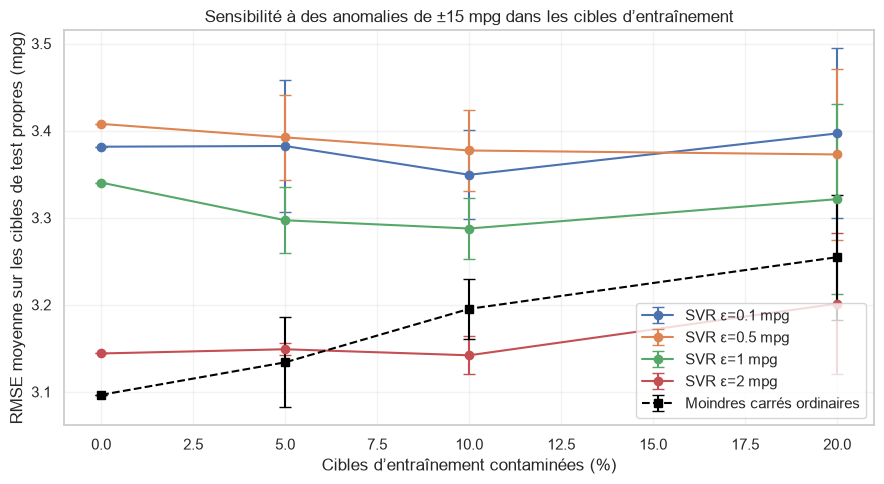

In [16]:
from sklearn.linear_model import LinearRegression

fractions_contamination = [0.0, 0.05, 0.10, 0.20]
graine_contamination = [3101, 3102, 3103, 3104, 3105]
amplitude_contamination = 15.0
X_train_controle = X_train.copy()
X_test_controle = X_test.copy()
y_train_controle = y_mpg_train.copy()
y_test_controle = y_mpg_test.copy()

lignes_contamination = []
for fraction in fractions_contamination:
    for graine in graine_contamination:
        rng_contamination = np.random.default_rng(graine)
        y_contamine = y_train_controle.copy()
        n_contamines = int(round(fraction * len(y_contamine)))
        indices_contamines = rng_contamination.choice(len(y_contamine), size=n_contamines, replace=False)
        n_positifs = n_contamines // 2
        signes = np.r_[np.ones(n_positifs), -np.ones(n_contamines - n_positifs)]
        rng_contamination.shuffle(signes)
        y_contamine[indices_contamines] += amplitude_contamination * signes

        # Les cinq méthodes reçoivent exactement le même vecteur contaminé à cette graine.
        for epsilon in valeurs_epsilon:
            modele = SVRLineaireFaitMaison(
                C=C_svr_retenu, epsilon=epsilon, tolerance=TOLERANCE_SVR,
                iterations_max=ITERATIONS_MAX_SVR,
            ).fit(X_train_controle, y_contamine)
            prediction = modele.predict(X_test_controle)
            lignes_contamination.append({
                "modèle": "SVR maison",
                "fraction contaminée": fraction,
                "epsilon": epsilon,
                "graine": graine,
                "observations contaminées": n_contamines,
                "MAE": mean_absolute_error(y_test_controle, prediction),
                "RMSE": np.sqrt(mean_squared_error(y_test_controle, prediction)),
                "R2": r2_score(y_test_controle, prediction),
                "vecteurs de support": modele.n_support_,
                "convergence": modele.converged_,
                "itérations": modele.n_sweeps_,
            })

        modele_moindres_carres = LinearRegression().fit(X_train_controle, y_contamine)
        prediction_moindres_carres = modele_moindres_carres.predict(X_test_controle)
        lignes_contamination.append({
            "modèle": "Moindres carrés ordinaires",
            "fraction contaminée": fraction,
            "epsilon": np.nan,
            "graine": graine,
            "observations contaminées": n_contamines,
            "MAE": mean_absolute_error(y_test_controle, prediction_moindres_carres),
            "RMSE": np.sqrt(mean_squared_error(y_test_controle, prediction_moindres_carres)),
            "R2": r2_score(y_test_controle, prediction_moindres_carres),
            "vecteurs de support": np.nan,
            "convergence": True,
            "itérations": np.nan,
        })

assert np.array_equal(X_train, X_train_controle) and np.array_equal(X_test, X_test_controle)
assert np.array_equal(y_mpg_train, y_train_controle) and np.array_equal(y_mpg_test, y_test_controle)
assert np.allclose(test["mpg"].to_numpy(dtype=float), y_test_controle)
resultats_contamination = pd.DataFrame(lignes_contamination)
resume_contamination = (
    resultats_contamination
    .groupby(["modèle", "fraction contaminée", "epsilon"], dropna=False)
    .agg(
        RMSE_moyenne=("RMSE", "mean"), RMSE_ecart_type=("RMSE", "std"),
        MAE_moyenne=("MAE", "mean"), MAE_ecart_type=("MAE", "std"),
        R2_moyen=("R2", "mean"),
        supports_moyens=("vecteurs de support", "mean"),
        taux_convergence=("convergence", "mean"),
        repetitions=("graine", "count"),
    )
    .reset_index()
)
print("Cibles de test propres et données d’origine inchangées; un vecteur contaminé partagé par les cinq modèles à chaque graine.")
print("Nombre de cibles modifiées par fraction :", {f: int(round(f * len(y_train_controle))) for f in fractions_contamination})
display(resume_contamination.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
for epsilon in valeurs_epsilon:
    courbe = resume_contamination[
        (resume_contamination["modèle"] == "SVR maison")
        & np.isclose(resume_contamination["epsilon"], epsilon)
    ].sort_values("fraction contaminée")
    ax.errorbar(courbe["fraction contaminée"] * 100, courbe["RMSE_moyenne"],
                yerr=courbe["RMSE_ecart_type"], marker="o", capsize=4,
                label=f"SVR ε={epsilon:g} mpg")
ols = resume_contamination[resume_contamination["modèle"] == "Moindres carrés ordinaires"].sort_values("fraction contaminée")
ax.errorbar(ols["fraction contaminée"] * 100, ols["RMSE_moyenne"], yerr=ols["RMSE_ecart_type"],
            marker="s", linestyle="--", color="black", capsize=4, label="Moindres carrés ordinaires")
ax.set_xlabel("Cibles d’entraînement contaminées (%)")
ax.set_ylabel("RMSE moyenne sur les cibles de test propres (mpg)")
ax.set_title("Sensibilité à des anomalies de ±15 mpg dans les cibles d’entraînement")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


### Lecture des résultats — contamination des cibles

Les moindres carrés ont la RMSE moyenne la plus faible sur les cibles propres (**3,097 mpg**) contre **3,144 mpg** pour le SVR maison à $\epsilon=2$, la meilleure des quatre valeurs de la grille propre. Quand 20 % des cibles d’entraînement reçoivent une anomalie de $\pm 15$ mpg, la RMSE moyenne des moindres carrés passe à **$3{,}255\pm0{,}072\,\mathrm{mpg}$**; celle du SVR à $\epsilon=2$ passe à **$3{,}201\pm0{,}081\,\mathrm{mpg}$**. Entre le cas propre et 20 % de contamination, la hausse des moyennes est donc d’environ **0,158 mpg** pour les moindres carrés et **0,057 mpg** pour ce SVR.

À 5 % de contamination, les moindres carrés restent légèrement meilleurs en moyenne; à 10 et 20 %, le SVR $\epsilon=2$ affiche une RMSE moyenne plus faible. Les dispersions entre les cinq graines sont toutefois du même ordre que plusieurs écarts entre méthodes. Ces résultats suggèrent une sensibilité relative moindre du SVR $\epsilon=2$ dans ce stress test, mais ne suffisent pas à établir un avantage statistique ou général.

L’effet dépend de $\epsilon$ : à 20 %, les RMSE moyennes du SVR pour $\epsilon\in\{0{,}1;\,0{,}5;\,1;\,2\}$ sont **3,397; 3,373; 3,321 et 3,201 mpg**. Une marge $\epsilon$ plus grande limite ici davantage l’impact des cibles contaminées, mais le SVR reste moins précis que les moindres carrés sur les données propres. Les deux méthodes ont des objectifs et régularisations différents, et cinq graines ne couvrent pas toute l’incertitude.


## 19. Analyse finale et conclusion

La synthèse s’appuie sur les analyses exploratoires de l’entraînement, la validation KNN interne, les deux discrétisations, la validation croisée des grilles SVC/SVR, les résultats du test réservé, le bruit gaussien et la contamination des cibles.

Les scores décrivent une partition de test unique. Les écarts-types des études de robustesse reposent sur cinq répétitions; la CV de classification et régression utilise trois plis. Les perturbations artificielles et la grille restreinte limitent la portée des conclusions.


In [17]:
ligne_lineaire = resultats_classification[resultats_classification["modèle"] == "SVM linéaire fait maison"].iloc[0]
ligne_rbf = resultats_classification[resultats_classification["modèle"] == "SVM RBF fait maison (SMO, OvR)"].iloc[0]
svr_maison = table_svr[table_svr["modèle"] == "SVR fait maison"].sort_values("epsilon")
print("Résumé des comparaisons finales (sans choisir un réglage sur le test) :")
print(f"- SVM linéaire maison : exactitude {ligne_lineaire['exactitude']:.3f}, F1 macro {ligne_lineaire['F1 macro']:.3f}.")
print(f"- SVM RBF maison : exactitude {ligne_rbf['exactitude']:.3f}, F1 macro {ligne_rbf['F1 macro']:.3f}.")
print("- Seuils quantiles appris sur l’entraînement (mpg) :", np.round(seuils_quantiles, 2))
print("- KNN retenu après validation interne :", meilleures_variables_knn, f"; k={meilleur_k}.")
print("- Vecteurs de support du SVR maison selon ε :", list(zip(svr_maison["epsilon"].tolist(), svr_maison["vecteurs de support"].astype(int).tolist())))
print("RMSE SVR maison moyenne à sigma=4 selon epsilon :")
print(resume_maison_bruit[resume_maison_bruit["sigma"] == 4.0][["epsilon", "RMSE_moyenne", "RMSE_ecart_type", "vecteurs de support_moyenne", "taux_convergence"]].round(3).to_string(index=False))
print("Ces scores sont estimés sur une partition de test unique, non des garanties de performance future.")

Résumé des comparaisons finales (sans choisir un réglage sur le test) :
- SVM linéaire maison : exactitude 0.750, F1 macro 0.750.
- SVM RBF maison : exactitude 0.738, F1 macro 0.743.
- Seuils quantiles appris sur l’entraînement (mpg) : [18.83 27.  ]
- KNN retenu après validation interne : ['displacement', 'weight', 'cylinders'] ; k=7.
- Vecteurs de support du SVR maison selon ε : [(0.1, 314), (0.5, 271), (1.0, 222), (2.0, 159)]
RMSE SVR maison moyenne à sigma=4 selon epsilon :
 epsilon  RMSE_moyenne  RMSE_ecart_type  vecteurs de support_moyenne  taux_convergence
     0.1         3.385            0.242                        316.8               1.0
     0.5         3.329            0.236                        297.0               1.0
     1.0         3.308            0.215                        272.4               1.0
     2.0         3.277            0.122                        230.4               1.0
Ces scores sont estimés sur une partition de test unique, non des garanties de perf

### Conclusion appuyée sur les résultats

L’analyse exploratoire sur l’entraînement montre une cible `mpg` étendue de 9 à 46,6, des associations inverses fortes avec la masse, la cylindrée et la puissance, une tendance positive selon l’année-modèle et des différences descriptives selon l’origine. Cinq puissances manquent dans l’entraînement (six dans la source). Les variables retenues, l’imputation KNN, le codage indicateur et la standardisation reposent sur les références d’entraînement; le test est transformé avec ces mêmes objets.

La validation KNN retient `displacement`, `weight` et `cylinders`, $k=7$, avec MAE 9,21 hp et RMSE 12,83 hp. Elle améliore les références moyenne et médiane, mais repose sur un seul masquage artificiel. La partition stratifiée produit des classes quantiles proches en proportions dans l’entraînement (33,3/33,0/33,6 %) et le test (31,3/36,3/32,5 %). À largeur égale, la classe élevée reste minoritaire à 11 %.

Les grilles stratifiées à trois plis sélectionnent $C=10$ pour le SVM linéaire (F1 macro moyen 0,813) et $C=1$, $\gamma=0{,}222$ pour RBF (0,843). Sur le test, le linéaire obtient F1 macro 0,750 et le RBF 0,743; le meilleur score CV de RBF ne se traduit donc pas par un gain observé sur ce test. Les performances changent avec les étiquettes à largeur égale : le SVC linéaire scikit-learn obtient F1 0,841, le linéaire maison 0,762 et les RBF 0,832. Le choix des seuils modifie ainsi la difficulté de classification.

Le SVR maison, désormais optimisé par gradient proximal accéléré sur le dual, converge pour les réglages CV et les essais rapportés. La grille retient $C=10$, $\epsilon=2$; sur le test propre sa RMSE est 3,144 mpg, proche de la référence scikit-learn. $\epsilon=2$ a aussi la plus faible RMSE absolue parmi les quatre valeurs testées et le moins de supports, mais cela reste lié à cette partition et à cette grille.

Le bruit gaussien ajoute seulement de petites variations de moyenne, comparables à la dispersion entre les cinq graines. Il ne permet pas de classer la stabilité des valeurs d’$\epsilon$. Le stress test de contamination est plus informatif pour les valeurs extrêmes : à 20 % de cibles altérées de $\pm 15$ mpg, la hausse moyenne de RMSE du SVR $\epsilon=2$ (0,057 mpg depuis le cas propre) est inférieure à celle des moindres carrés (0,158 mpg), et sa RMSE moyenne est 3,201 contre 3,255 mpg. L’OLS reste meilleur sur le cas propre, et les écarts de contamination sont proches des écarts-types entre graines; l’indication de robustesse du SVR $\epsilon=2$ est donc suggestive, pas concluante.

Les limites sont une séparation de test, un masquage KNN, trois plis pour les grilles, cinq graines par expérience de robustesse et des contaminants artificiels de grande amplitude. D’autres partitions et répétitions, une validation imbriquée et des scénarios d’erreur plus réalistes seraient nécessaires pour généraliser les comparaisons.
